---
title: "EPS: alcohol consumption transitions"
subtitle: "Survey design, pooled models and person-blocked validation"
author: "Andres Gonzalez Santa Cruz"
lang: en
format:
  html:
    theme: journal
    css: [_lib/styles.css, _lib/prediction_metrics_compact.css]
    toc: true
    toc-location: left
    toc-depth: 2
    number-sections: false
    code-fold: true
    code-summary: "Show R code"
    code-tools: true
    embed-resources: true
    self-contained: true
    html-math-method: mathml
execute:
  echo: true
  warning: false
  error: false
---

**Quick orientation:** results are recomputed using EPS design; all pairs of each person stay together. Gamma and lognormal are compared using the same information, retaining N0, FD and C1–C4.


## Saved results: quick reading

- **Best average score:** Lognormal. Comparing lognormal with Gamma changes category probabilities by a mean 0.35 percentage points; Gamma is retained.
- **Education:** covariate, interaction and stratification alternatives are compared. Current differences are inconclusive.
- **History:** Earlier history did not clearly improve adjusted prediction, including education interactions. This does not establish Markov behaviour.
- **Uncertainty:** EPS design is primary, with every person's pairs kept together; 1,000 whole-person replicates provide a sensitivity.
- **Exploratory annualization:** restarts at the same penalty change an individual probability by up to 7.9 percentage points; exploring penalties as well raises this to 27.9. This is not yet a stable annual engine.
- **Future use:** annual matrices are model-derived; ENPG calibration and independent validation remain pending.

This summary is generated from verified tables after notebook execution.

In [1]:
#| label: eps-session-setup
.t0 <- Sys.time()
ep_lang <- "en"
if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_ALL", "English_United States.utf8")) else invisible(Sys.setlocale("LC_CTYPE", ""))
suppressMessages(here::i_am("__andres_control/eps_markov_transitions_EN.ipynb"))
required <- c("survey","haven","nnet","MASS","ggplot2","jsonlite","IRdisplay","htmltools","knitr")
stopifnot(all(vapply(required,requireNamespace,logical(1),quietly=TRUE)))
ep_checks <- list(); ep_warnings <- character()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.03 minutes


In [2]:
#| label: eps-shared-definitions
.t0 <- Sys.time()
.t0 <- Sys.time()
# Shared computational source embedded in both language versions of the notebook.
# All confidential row-level objects stay in memory; exports are aggregates only.
ep_seed <- 1240138L
ep_B <- 1000L
ep_repeats <- 3L
ep_K <- 5L
ep_kgrid <- c(10, 30, 100, 300, 1000)
ep_ST <- c("N0", "FD", "C1", "C2", "C3", "C4")
ep_Y <- c("NC", "C1", "C2", "C3", "C4")
ep_ages <- c("18-29", "30-44", "45-59", "60-65")
ep_periods <- c("VI_VII", "VII_VIII")
ep_palette <- c(blue = "#216A83", rust = "#B16031", olive = "#637A44", grey = "#777777",
                light = "#F4F7F8", heat = "#679CAC", pale = "#E8EFF1")
ep_tr <- function(en, es) if (identical(ep_lang, "es")) es else en
ep_check <- function(ok, label) {
  stopifnot(isTRUE(ok))
  ep_checks[[label]] <<- TRUE
  invisible(TRUE)
}
ep_theme <- function() ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(panel.grid.minor = ggplot2::element_blank(), legend.position = "bottom",
                 plot.title = ggplot2::element_text(face = "bold"))
ep_save <- function(x, name) utils::write.csv(x, file.path(ep_out, paste0(name, ".csv")),
                                           row.names = FALSE, na = "", fileEncoding = "UTF-8")
ep_show <- function(x, en, es, digits = 3) {
  IRdisplay::display_html(as.character(htmltools::div(style = "overflow-x:auto;max-height:640px;overflow-y:auto",
    htmltools::HTML(knitr::kable(x, format = "html", digits = digits, row.names = FALSE,
                               caption = ep_tr(en, es))))))
}
ep_fig <- function(p, name, w = 10, h = 6) {
  dest <- file.path(ep_out, ep_lang)
  dir.create(dest, showWarnings = FALSE)
  ggplot2::ggsave(file.path(dest, paste0(name, ".png")), p, width = w, height = h, dpi = 170, bg = "white")
  ggplot2::ggsave(file.path(dest, paste0(name, ".pdf")), p, width = w, height = h,
                 device = grDevices::cairo_pdf, bg = "white")
  if (ep_lang == "es") file.copy(file.path(dest, paste0(name, ".png")), file.path(ep_out, paste0(name, ".png")), overwrite = TRUE)
  IRdisplay::display_png(file = file.path(dest, paste0(name, ".png")))
}
ep_warn <- function(expr) withCallingHandlers(expr, warning = function(w) {
  msg <- conditionMessage(w)
  ep_warnings <<- c(ep_warnings, msg)
  invokeRestart("muffleWarning")
})
ep_age <- function(a) factor(as.character(cut(a, c(18, 30, 45, 60, 66), right = FALSE,
                                             labels = ep_ages)), levels = ep_ages)
ep_key <- function(d, v) if (length(v)) do.call(paste, c(lapply(d[v], as.character), sep = "|")) else rep("All", nrow(d))
ep_cat <- function(current, g, sex) {
  lo <- ifelse(sex == "Women", 20, 40); hi <- ifelse(sex == "Women", 40, 60)
  top <- ifelse(sex == "Women", 60, 100)   # C3/C4 boundary (included in C3): women 60 g/day, men 100 g/day
  ans <- rep(NA_character_, length(g)); ok <- current %in% 1 & is.finite(g) & g > 0
  ans[ok & g < lo] <- "C1"; ans[ok & g >= lo & g < hi] <- "C2"
  ans[ok & g >= hi & g <= top] <- "C3"; ans[ok & g > top] <- "C4"
  ans
}
ep_qsignal <- function(d) {
  s <- as.matrix(d[paste0("f13_", 1:3)]); q <- as.matrix(d[paste0("f15_", 1:3)])
  positive <- s == 1 & is.finite(q) & q > 0 & q < 70
  hit <- rowSums(positive & q >= ifelse(d$sex == "Women", 4, 5), na.rm = TRUE) > 0
  known <- rowSums((s == 2) | positive, na.rm = TRUE) == 3
  ifelse(d$current %in% 1, ifelse(hit, 1, ifelse(known, 0, NA_real_)), NA_real_)
}
ep_load <- function() {
  source(here::here("_tools", "acc_data.R"))
  ep_out <<- here::here(Sys.getenv("EPS_MARKOV_OUTPUT", "__andres_control/eps_markov_outputs"))
  dir.create(ep_out, showWarnings = FALSE, recursive = TRUE)
  cells <- jsonlite::read_json(here::here("__andres_control", "eps_alcohol_prevalencia_persistencia.ipynb"))$cells
  run <- function(label) {
    src <- vapply(cells, function(x) paste(unlist(x$source), collapse = ""), "")
    hit <- which(startsWith(src, paste0("#| label: ", label, "\n")))
    stopifnot(length(hit) == 1)
    eval(parse(text = src[hit]), globalenv())
  }
  run("eps-setup")
  # Redirect only this session's exported input audit, never modify the source notebook.
  eps_save <<- ep_save
  run("eps-inputs"); run("eps-harmonize")
  if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_CTYPE", "English_United States.utf8"))
  # Do not inherit VI's weights-only placeholder PSU/stratum as a real design.
  eps_data$VI$psu <<- NA_real_; eps_data$VI$strata <<- NA_real_
  ep_time <<- data.frame(period = c(ep_periods, "VI_VIII"), from = c("VI", "VII_presencial", "VI"),
    to = c("VII_presencial", "VIII", "VIII"), years = c(3.671, 4.03, 7.693),
    min_years = c(3.285, 3.55, 7.110), max_years = c(4.057, 4.49, 8.277))
  # Design IDs are sourced from published weight files, not invented geographic codes.
  wf <- list.files(eps_root, pattern = "[.]dta$", full.names = TRUE, recursive = TRUE, ignore.case = TRUE)
  wf <- wf[grepl("factor|fact_exp", wf, ignore.case = TRUE)]
  designs <- lapply(wf, function(f) {
    h <- haven::read_dta(f, n_max = 0)
    if (!all(c("folio_n20", "cluster_ID", "strata_ID") %in% names(h))) return(NULL)
    d <- haven::read_dta(f)
    data.frame(id = as.character(d$folio_n20), psu = as.character(d$cluster_ID), strata = as.character(d$strata_ID))
  })
  dd <- unique(do.call(rbind, designs)); ep_check(!anyDuplicated(dd$id), "Published design codes agree across files")
  ep_design_map <<- dd
  # Known deaths at VIII are competing events, not alcohol abstention or recoverable missing outcomes.
  deathfiles <- list.files(file.path(eps_root, "Bases de datos EPS VIII Ronda", "BBDD_FALL"),
                          pattern = "[.]dta$", full.names = TRUE, ignore.case = TRUE)
  ep_dead8 <<- unique(unlist(lapply(deathfiles, function(f) {
    h <- haven::read_dta(f, n_max = 0)
    if ("folio_n20" %in% names(h)) as.character(haven::read_dta(f, col_select = "folio_n20")$folio_n20) else character()
  })))
  av <- do.call(rbind, lapply(names(eps_data), function(w) {
    d <- eps_data[[w]]; j <- match(d$id, dd$id)
    data.frame(wave = w, persons = nrow(d), design_identified = sum(!is.na(j)), design_unidentified = sum(is.na(j)))
  }))
  ep_save(av, "design_availability")
  ep_check(all(c("strata_ID", "cluster_ID", "factor_Panel_2015") %in% names(eps_panel_weights$VI_VII)),
           "VI-VII longitudinal weight and design are available")
  invisible(av)
}
ep_waves <- function(grams = 12) {
  W <- do.call(rbind, lapply(names(eps_data), function(w) {
    d <- eps_data[[w]]; j <- match(d$id, ep_design_map$id); g <- d$grams_day * grams / 12
    data.frame(id = d$id, wave = w, age = d$age, sex = d$sex, education = d$education,
      weight_xs = d$weight, psu = ep_design_map$psu[j], strata = ep_design_map$strata[j],
      current = ifelse(d$contradiction, NA_real_, d$current), grams = g,
      cat = ifelse(d$contradiction, NA_character_, ep_cat(d$current, g, d$sex)), signal = ep_qsignal(d))
  }))
  W$prior_use <- FALSE; W$longterm <- FALSE; W$two_wave_negative <- FALSE
  for (w in c("VII_presencial", "VIII")) {
    ii <- which(W$wave == w)
    for (j in which(ep_time$to == w)) {
      tm <- ep_time[j, ]; a <- W[W$wave == tm$from, ]; ix <- match(W$id[ii], a$id)
      ok <- !is.na(ix) & a$sex[ix] == W$sex[ii] & W$age[ii] - a$age[ix] >= floor(tm$min_years) &
        W$age[ii] - a$age[ix] <= ceiling(tm$max_years)
      ok <- ok %in% TRUE
      W$prior_use[ii] <- W$prior_use[ii] | (ok & (a$current[ix] %in% 1 | a$prior_use[ix] %in% TRUE))
      neg <- ok & a$current[ix] %in% 0 & W$current[ii] %in% 0
      W$two_wave_negative[ii] <- W$two_wave_negative[ii] | neg
      if (tm$min_years >= 4) W$longterm[ii] <- W$longterm[ii] | neg
    }
  }
  W$longterm <- W$longterm & !W$prior_use
  W$two_wave_negative <- W$two_wave_negative & !W$prior_use
  W$state <- ifelse(W$current %in% 1, W$cat,
                     ifelse(W$current %in% 0, ifelse(W$prior_use, "FD", "N0"), NA_character_))
  W
}
ep_make_risk <- function(W, official = TRUE) {
  out <- lapply(ep_periods, function(p) {
    tm <- ep_time[ep_time$period == p, ]; a <- W[W$wave == tm$from, ]; b <- W[W$wave == tm$to, ]
    a <- a[a$age >= 18 & a$age <= 65 & !is.na(a$sex), ]
    w <- a$weight_xs
    if (p == "VI_VII" && official) {
      pw <- eps_panel_weights$VI_VII; j <- match(a$id, as.character(pw$folio_n20)); keep <- !is.na(j)
      a <- a[keep, ]; w <- as.numeric(pw$factor_Panel_2015[j[keep]])
    }
    death <- p == "VII_VIII" & a$id %in% ep_dead8
    a <- a[!death, ]; w <- w[!death]
    j <- match(a$id, b$id); z <- b[j, ]
    valid <- !is.na(j) & a$sex == z$sex & z$age - a$age >= floor(tm$min_years) & z$age - a$age <= ceiling(tm$max_years)
    valid <- valid %in% TRUE
    data.frame(id = a$id, period = p, age = a$age, sex = a$sex, edu = a$education,
      wbase = w, psu = a$psu, strata = a$strata, years = tm$years,
      state0 = a$state, state1 = ifelse(valid, z$state, NA_character_), linked = valid,
      grams0 = a$grams, grams1 = ifelse(valid, z$grams, NA_real_),
      signal0 = a$signal, signal1 = ifelse(valid, z$signal, NA_real_),
      longterm0 = a$longterm, longterm1 = ifelse(valid, z$longterm, NA),
      neg_history0 = a$two_wave_negative, official = p == "VI_VII" && official)
  })
  d <- do.call(rbind, out)
  d$period <- factor(d$period, levels = ep_periods); d$sex <- factor(d$sex, levels = c("Men", "Women"))
  d$age_group <- ep_age(d$age)
  d$edu_missing <- as.numeric(is.na(d$edu)); d$edu_num <- match(d$edu, eps_edu_levels) - 1
  d$edu_num[is.na(d$edu_num)] <- 0
  d$edu <- factor(ifelse(is.na(d$edu), "Missing", d$edu), levels = c(eps_edu_levels, "Missing"))
  d$state0 <- factor(d$state0, levels = ep_ST)
  d$current0 <- as.numeric(d$state0 %in% paste0("C", 1:4))
  d$lg0 <- ifelse(d$current0 == 1 & d$grams0 > 0, log(d$grams0), 0)
  d$history_early <- factor(ifelse(d$neg_history0, "repeated_negative", "unresolved"))
  d$s0 <- !is.na(d$state0); d$s1 <- !is.na(d$state1); d$complete <- d$s0 & d$linked & d$s1
  d$y1 <- factor(ifelse(d$state1 %in% c("N0", "FD"), "NC", d$state1), levels = ep_Y)
  d$row_id <- paste(d$id, d$period, sep = ":")
  d$mult <- 1
  d
}
ep_x <- function(d, formula, terms_keep = NULL) {
  x <- stats::model.matrix(formula, d)
  if (!is.null(terms_keep)) x <- x[, terms_keep, drop = FALSE]
  x
}
ep_binary_fit <- function(d, y, formula, w) {
  X <- ep_x(d, formula); keep <- w > 0 & is.finite(y) & stats::complete.cases(X)
  if (!any(keep)) stop("No usable training rows in binary model")
  if (length(unique(y[keep])) == 1L) return(list(constant = y[keep][1]))
  X <- X[keep, , drop = FALSE]; ww <- w[keep] / mean(w[keep])
  q <- qr(X * sqrt(ww)); cols <- sort(q$pivot[seq_len(q$rank)])
  fit <- ep_warn(stats::glm.fit(X[, cols, drop = FALSE], y[keep], weights = ww,
    family = stats::quasibinomial(), control = stats::glm.control(maxit = 80)))
  if(!isTRUE(fit$converged)) fit <- ep_warn(stats::glm.fit(X[,cols,drop=FALSE],y[keep],weights=ww,
    family=stats::quasibinomial(),control=stats::glm.control(maxit=250),start=fit$coefficients))
  stopifnot(isTRUE(fit$converged),all(is.finite(fit$coefficients)))
  list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], converged = fit$converged)
}
ep_binary_prob <- function(o, d) {
  if (!is.null(o$constant)) return(rep(o$constant, nrow(d)))
  as.numeric(stats::plogis(ep_x(d, o$formula, o$columns) %*% o$coef))
}
ep_wquant <- function(x, w, p) {
  i <- order(x); xx <- x[i]; ww <- w[i]; cp <- cumsum(ww) / sum(ww)
  vapply(p, function(pp) xx[which(cp >= pp)[1]], 1)
}
ep_ipw_fit <- function(r) {
  lapply(stats::setNames(ep_periods, ep_periods), function(p) {
    d <- r[r$period == p, ]; w <- d$wbase * d$mult
    f0 <- ~ sex + age_group + edu_num + edu_missing
    f1 <- ~ state0 + sex + age_group + edu_num + edu_missing
    a <- ep_binary_fit(d, as.numeric(d$s0), f0, w)
    i <- d$s0; b <- ep_binary_fit(d[i, ], as.numeric(d$linked[i]), f1, w[i])
    i <- d$s0 & d$linked; c <- ep_binary_fit(d[i, ], as.numeric(d$s1[i]), f1, w[i])
    z <- d[d$complete, ]; prob <- pmax(ep_binary_prob(a, z) * ep_binary_prob(b, z) * ep_binary_prob(c, z), .02)
    raw <- z$wbase / prob
    list(base = a, link = b, final = c, cap = ep_wquant(raw, z$mult, c(.01, .99)))
  })
}
ep_ipw_apply <- function(r, fit) {
  out <- lapply(ep_periods, function(p) {
    z <- r[r$period == p & r$complete, ]; if (!nrow(z)) return(z)
    o <- fit[[p]]
    z$p_obs <- pmax(ep_binary_prob(o$base, z) * ep_binary_prob(o$link, z) * ep_binary_prob(o$final, z), .02)
    z$untrimmed <- z$wbase / z$p_obs
    z$wcorrected <- pmin(pmax(z$untrimmed, o$cap[1]), o$cap[2])
    z$wn <- z$wcorrected * z$mult
    # Fix each period's contribution to its original observed-pair count.
    z$wn <- z$wn / sum(z$wn) * ep_period_mass[[p]]
    z
  })
  d <- do.call(rbind, out); rownames(d) <- NULL; d
}
ep_design <- function() {
  v <- eps_data$VII_presencial
  j <- match(v$id, ep_design_map$id)
  m <- data.frame(id=v$id, psu=ep_design_map$psu[j], strata=ep_design_map$strata[j])
  ep_check(!anyDuplicated(m$id) && !anyNA(m), "Every risk-set ID has one published PSU and stratum")
  ep_check(all(ep_risk$id %in% m$id), "Risk-set persons belong to the full VII design frame")
  m$w <- 1
  options(survey.lonely.psu = "adjust", survey.adjust.domain.lonely = TRUE)
  ds <- survey::svydesign(ids = ~psu, strata = ~strata, weights = ~w, data = m, nest = TRUE)
  # Replication factors are shared by all pairs of an ID; official period weights are applied later.
  rp <- survey::as.svrepdesign(ds, type = "JKn", mse = TRUE, compress = TRUE)
  rw <- as.matrix(stats::weights(rp, type = "analysis"))
  list(master = m, survey = ds, replicate = rp, multipliers = rw)
}
ep_person_mult <- function(master) {
  mult <- tabulate(sample.int(nrow(master), nrow(master), replace = TRUE), nbins = nrow(master))
  stats::setNames(mult, master$id)
}
ep_formula <- function(education = "ordinal", history = FALSE, literal_jrt = FALSE) {
  if (literal_jrt) return(~ state0 * age_group + state0 * sex + sex * age_group + period)
  ed <- switch(education, none = "", ordinal = " + edu_num + edu_missing",
    interaction = " + edu_num * (current0 + sex + age_group) + edu_missing",
    categorical = " + edu")
  stats::as.formula(paste0("~ state0 + sex * age_group + period + lg0", ed,
                           if (history) " + earlier_state + earlier_lg" else ""))
}
ep_matrix_fit <- function(d, formula, y, family) {
  X <- ep_x(d, formula); w <- d$wn / mean(d$wn[d$wn > 0]); keep <- w > 0
  q <- qr(X[keep, , drop = FALSE] * sqrt(w[keep])); cols <- sort(q$pivot[seq_len(q$rank)])
  XX <- X[, cols, drop = FALSE]; positive <- y > 0 & keep
  if (family == "gamma") {
    fit <- ep_warn(stats::glm.fit(XX[positive, , drop = FALSE], y[positive], weights = w[positive],
      family = stats::Gamma("log"), control = stats::glm.control(maxit = 100)))
    stopifnot(isTRUE(fit$converged),all(is.finite(fit$coefficients)))
    mu <- as.numeric(exp(XX[positive, , drop = FALSE] %*% fit$coefficients))
    ratio <- y[positive] / mu; ww <- w[positive] / sum(w[positive])
    # Survey weights are frequency importance weights, not inverse residual variances.
    loss <- function(a) { sh <- exp(a); -sum(ww * (sh * log(sh) - lgamma(sh) + (sh - 1) * log(ratio) - sh * ratio)) }
    shape <- exp(stats::optimize(loss, c(log(.03), log(1000)))$minimum)
    list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], shape = shape, kind = family)
  } else {
    fit <- stats::lm.wfit(XX[positive, , drop = FALSE], log(y[positive]), w[positive])
    sigma <- sqrt(sum(w[positive] * fit$residuals^2) / sum(w[positive]))
    list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], sigma = sigma, kind = family)
  }
}
ep_class_fit <- function(d, formula, kind, positive = FALSE) {
  cls <- if (positive) ep_Y[-1] else ep_Y
  y <- factor(as.character(d$y1), levels = cls, ordered = kind == "ordinal")
  good <- d$wn > 0 & !is.na(y); d <- d[good, ]; y <- droplevels(y[good])
  w <- d$wn / mean(d$wn)
  if (nlevels(y) == 1) return(list(constant = levels(y), classes = cls))
  X <- ep_x(d, formula)
  X <- X[, colnames(X) != "(Intercept)", drop = FALSE]
  q <- qr(cbind(1, X) * sqrt(w)); keep <- setdiff(sort(q$pivot[seq_len(q$rank)]), 1) - 1
  cols <- colnames(X)[keep]; XX <- X[, keep, drop = FALSE]
  dat <- data.frame(y = y, XX, w = w, check.names = FALSE)
  names(dat)[seq_along(cols) + 1] <- paste0("x", seq_along(cols))
  f <- stats::as.formula(paste("y ~", paste(paste0("x", seq_along(cols)), collapse = " + ")))
  if (kind == "ordinal" && nlevels(y) > 2) {
    fit <- tryCatch(ep_warn(MASS::polr(f, data = dat, weights = w,
      method = "logistic", Hess = FALSE, control = list(maxit = 500))), error = identity)
    valid <- !inherits(fit,"error") && isTRUE(fit$convergence==0) && all(is.finite(stats::coef(fit)))
    if (!valid) {
      # Sparse transport samples can make polr's binary-GLM starting values nonfinite.
      # Weighted marginal thresholds with zero slopes give a finite ordered start.
      mass <- as.numeric(tapply(w,y,sum)); cuts <- stats::qlogis(head(cumsum(mass)/sum(mass),-1))
      stopifnot(all(is.finite(cuts)),all(diff(cuts)>0))
      fit <- ep_warn(MASS::polr(f,data=dat,weights=w,method="logistic",Hess=FALSE,
        start=c(rep(0,length(cols)),cuts),control=list(maxit=1000)))
      ep_warnings <<- c(ep_warnings,"Ordinal fit restarted from weighted marginal thresholds")
    }
  } else fit <- ep_warn(nnet::multinom(f, data = dat, weights = w, decay = .1, trace = FALSE, maxit = 500))
  if(!is.null(fit$convergence)) stopifnot(fit$convergence==0)
  stopifnot(all(is.finite(stats::coef(fit))))
  list(fit = fit, formula = formula, columns = cols, classes = cls, observed = levels(y))
}
ep_class_prob <- function(o, d) {
  ans <- matrix(0, nrow(d), length(o$classes), dimnames = list(NULL, o$classes))
  if (!is.null(o$constant)) { ans[, o$constant] <- 1; return(ans) }
  x <- ep_x(d, o$formula, o$columns); nd <- as.data.frame(x); names(nd) <- paste0("x", seq_len(ncol(nd)))
  p <- ep_warn(stats::predict(o$fit, nd, type = "probs"))
  if (is.null(dim(p))) {
    if (nrow(d) == 1 && length(p) == length(o$observed)) p <- matrix(p, 1, dimnames = list(NULL, o$observed))
    else if (length(o$observed) == 2) p <- cbind(1 - p, p)
    else stop("Unexpected probability dimensions")
  }
  if (is.null(colnames(p))) colnames(p) <- o$observed
  stopifnot(all(colnames(p) %in% o$classes))
  ans[, colnames(p)] <- p
  ans
}
ep_Afit <- function(d, k = 100, education = FALSE) {
  by <- c("sex", "age_group", if (education) "edu")
  count <- function(z) {
    t <- tapply(z$wn, list(factor(z$state0, ep_ST), factor(z$y1, ep_Y)), sum)
    t[is.na(t)] <- 0; t
  }
  shrink <- function(x, p, k) (x + k * p) / (rowSums(x) + k)
  global <- shrink(count(d), matrix(.2, 6, 5), .5)
  per <- lapply(split(d, d$period, drop = TRUE), function(dp) {
    pg <- shrink(count(dp), global, k)
    ps <- lapply(split(dp, dp$sex, drop = TRUE), function(ds) shrink(count(ds), pg, k))
    cells <- lapply(split(dp, ep_key(dp, by)), function(z) shrink(count(z), ps[[as.character(z$sex[1])]], k))
    list(global = pg, sex = ps, cells = cells)
  })
  list(per = per, global = global, by = by, k = k)
}
ep_Aprob <- function(o, d) {
  keys <- ep_key(d, o$by)
  ans <- matrix(NA_real_, nrow(d), 5, dimnames = list(NULL, ep_Y))
  for (i in seq_len(nrow(d))) {
    op <- o$per[[as.character(d$period[i])]]
    mat <- if (is.null(op)) o$global else if (!is.null(op$cells[[keys[i]]])) op$cells[[keys[i]]] else op$global
    ans[i, ] <- mat[as.character(d$state0[i]), ]
  }
  ans
}
ep_models <- list(
  A = list(kind = "matrix", education = FALSE), A_education = list(kind = "matrix", education = TRUE),
  Multinomial = list(kind = "multinomial", education = "ordinal"),
  Gamma = list(kind = "gamma", education = "ordinal"),
  Lognormal = list(kind = "lognormal", education = "ordinal"),
  Ordinal_two_part = list(kind = "ordinal", education = "ordinal"),
  NonPO_two_part = list(kind = "nonpo", education = "ordinal"),
  Ordinal_single = list(kind = "single", education = "ordinal"),
  JRT_reference = list(kind = "jrt", education = "none"),
  Gamma_no_education = list(kind = "gamma", education = "none"),
  Gamma_education_interaction = list(kind = "gamma", education = "interaction"),
  Lognormal_education_interaction = list(kind = "lognormal", education = "interaction"))
ep_main_models <- c("A", "Multinomial", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "JRT_reference")
ep_fit <- function(d, name, k = 100, history = FALSE) {
  spec <- ep_models[[name]]
  if (spec$kind == "matrix") return(list(kind = "matrix", amount = ep_Afit(d, k, spec$education)))
  f <- ep_formula(spec$education, history = history, literal_jrt = spec$kind == "jrt")
  if (spec$kind %in% c("single", "jrt", "multinomial")) return(list(kind = "class",
    amount = ep_class_fit(d, f, if (spec$kind == "multinomial") "multinomial" else "ordinal")))
  p <- ep_binary_fit(d, as.numeric(d$y1 != "NC"), f, d$wn)
  dc <- d[d$y1 != "NC", ]
  amount <- if (spec$kind %in% c("ordinal", "nonpo")) ep_class_fit(dc, f, if(spec$kind == "ordinal") "ordinal" else "multinomial", TRUE) else ep_matrix_fit(dc, f, dc$grams1, spec$kind)
  list(kind = spec$kind, participation = p, amount = amount)
}
ep_prob <- function(o, d) {
  if (o$kind == "matrix") p <- ep_Aprob(o$amount, d)
  else if (o$kind == "class") p <- ep_class_prob(o$amount, d)
  else {
    pc <- ep_binary_prob(o$participation, d)
    if (o$kind %in% c("ordinal", "nonpo")) pa <- ep_class_prob(o$amount, d)
    else {
      a <- o$amount; eta <- as.numeric(ep_x(d, a$formula, a$columns) %*% a$coef)
      cuts <- cbind(ifelse(d$sex == "Women", 20, 40), ifelse(d$sex == "Women", 40, 60), ifelse(d$sex == "Women", 60, 100))
      F <- if (o$kind == "gamma") stats::pgamma(cuts, shape = a$shape, scale = exp(eta) / a$shape) else
        stats::pnorm((log(cuts) - eta) / a$sigma)
      pa <- cbind(F[, 1], F[, 2] - F[, 1], F[, 3] - F[, 2], 1 - F[, 3])
    }
    p <- cbind(1 - pc, pc * pa); colnames(p) <- ep_Y
  }
  p <- pmax(p, 0); p <- p / rowSums(p)
  stopifnot(all(is.finite(p)), max(abs(rowSums(p) - 1)) < 1e-10, identical(colnames(p), ep_Y))
  p
}
ep_loss <- function(P, y) {
  # One numerical floor and one scoring implementation for scores AND paired contrasts.
  Q <- pmax(P, 1e-8); Q <- Q / rowSums(Q)
  Y <- diag(5)[as.integer(y), , drop = FALSE]
  data.frame(logloss = -log(Q[cbind(seq_len(nrow(Q)), as.integer(y))]),
    brier = rowSums((P - Y)^2), correct = max.col(P, ties.method = "first") == as.integer(y))
}
ep_fold <- function(ids, k = 5, seed = ep_seed) {
  set.seed(seed); uu <- sort(unique(ids)); stats::setNames(sample(rep(seq_len(k), length.out = length(uu))), uu)
}
ep_tune <- function(r, education = FALSE, seed = ep_seed) {
  f <- ep_fold(r$id, 3, seed); loss <- matrix(0, 3, length(ep_kgrid)); mass <- numeric(3)
  for (j in 1:3) {
    tr <- r[f[r$id] != j, ]; te <- r[f[r$id] == j, ]; nu <- ep_ipw_fit(tr)
    a <- ep_ipw_apply(tr, nu); b <- ep_ipw_apply(te, nu)
    mass[j] <- sum(b$wn)
    for (k in seq_along(ep_kgrid)) {
      pr <- ep_Aprob(ep_Afit(a, ep_kgrid[k], education), b)
      loss[j, k] <- sum(b$wn * ep_loss(pr, b$y1)$logloss)
    }
  }
  s <- colSums(loss) / sum(mass)
  list(k = ep_kgrid[which.min(s)], scores = data.frame(k = ep_kgrid, logloss = s, education = education))
}
ep_cv <- function(r, model_names = names(ep_models), repeats = ep_repeats) {
  ids <- ep_d$row_id; N <- length(ids); pred <- lapply(model_names, function(z) array(NA_real_, c(N, 5, repeats)))
  names(pred) <- model_names; weights <- matrix(NA_real_, N, repeats); audits <- list(); tunes <- list(); kk <- 0
  for (rep in seq_len(repeats)) {
    folds <- ep_fold(r$id, ep_K, ep_seed + rep)
    for (f in seq_len(ep_K)) {
      tr <- r[folds[r$id] != f, ]; te <- r[folds[r$id] == f, ]
      ep_check(!length(intersect(tr$id, te$id)), paste0("Disjoint persons CV ", rep, ":", f))
      nu <- ep_ipw_fit(tr); a <- ep_ipw_apply(tr, nu); b <- ep_ipw_apply(te, nu)
      ix <- match(b$row_id, ids); weights[ix, rep] <- b$wcorrected
      ka <- ep_tune(tr, FALSE, ep_seed + 100 * rep + f)
      ke <- ep_tune(tr, TRUE, ep_seed + 100 * rep + f)
      kk <- kk + 1
      tunes[[kk]] <- rbind(data.frame(rep = rep, fold = f, ka$scores), data.frame(rep = rep, fold = f, ke$scores))
      audits[[kk]] <- data.frame(rep = rep, fold = f, train_persons = length(unique(tr$id)), test_persons = length(unique(te$id)),
        test_pairs = nrow(b), overlap = 0L, IPW_training_only = TRUE, k_A = ka$k, k_A_education = ke$k)
      for (nm in model_names) pred[[nm]][ix, , rep] <- ep_prob(ep_fit(a, nm, if (nm == "A_education") ke$k else ka$k), b)
      cat(sprintf("CV repeat %d/%d, fold %d/%d complete\n", rep, repeats, f, ep_K))
    }
    # Undo fold-specific normalisation in scores by fixing period totals, not equal fold totals.
    for (p in ep_periods) { ii <- ep_d$period == p; weights[ii, rep] <- weights[ii, rep] / sum(weights[ii, rep]) * ep_period_mass[[p]] }
  }
  ep_check(all(vapply(pred, function(x) all(is.finite(x)), TRUE)), "Every held-out prediction is finite")
  list(pred = pred, weights = weights, audit = do.call(rbind, audits), tuning = do.call(rbind, tunes))
}
ep_cv_tables <- function(cv) {
  scores <- list(); losses <- list(); means <- list()
  for (nm in names(cv$pred)) {
    ar <- cv$pred[[nm]]; lr <- lapply(seq_len(dim(ar)[3]), function(j) ep_loss(ar[, , j], ep_d$y1))
    losses[[nm]] <- Reduce("+", lapply(seq_along(lr), function(j) as.matrix(lr[[j]]) * cv$weights[, j])) /
      rowSums(cv$weights)
    means[[nm]] <- Reduce("+",lapply(seq_len(dim(ar)[3]),function(j) ar[,,j]*cv$weights[,j])) / rowSums(cv$weights)
    colnames(means[[nm]]) <- ep_Y
    for (j in seq_along(lr)) scores[[length(scores) + 1]] <- data.frame(model = nm, repeat_id = j,
      logloss = stats::weighted.mean(lr[[j]]$logloss, cv$weights[, j]),
      brier = stats::weighted.mean(lr[[j]]$brier, cv$weights[, j]),
      accuracy = stats::weighted.mean(lr[[j]]$correct, cv$weights[, j]))
  }
  s <- do.call(rbind, scores); summary <- stats::aggregate(cbind(logloss, brier, accuracy) ~ model, s, mean)
  summary <- summary[order(summary$logloss), ]; rownames(summary) <- NULL
  list(scores = s, summary = summary, loss = losses, prob = means, w = rowMeans(cv$weights))
}
ep_score_contrasts <- function(cvtab) {
  d <- ep_d; d$wcv <- cvtab$w
  opts <- options(survey.lonely.psu = "adjust"); on.exit(options(opts))
  ds <- survey::svydesign(ids = ~psu, strata = ~strata, weights = ~wcv, data = d, nest = TRUE)
  pairs <- list(c("Lognormal", "Gamma"), c("Gamma", "A"), c("Lognormal", "A"),
    c("NonPO_two_part", "Ordinal_two_part"),
    c("Ordinal_two_part", "Gamma"), c("Ordinal_single", "Gamma"), c("Multinomial", "Gamma"),
    c("A_education", "A"), c("Gamma", "Gamma_no_education"), c("Gamma_education_interaction", "Gamma"),
    c("Lognormal_education_interaction", "Lognormal"))
  out <- lapply(pairs, function(z) {
    ds$variables$difference <- cvtab$loss[[z[1]]][, "logloss"] - cvtab$loss[[z[2]]][, "logloss"]
    m <- survey::svymean(~difference, ds); se <- sqrt(stats::vcov(m)[1, 1]); v <- as.numeric(stats::coef(m))
    crit <- stats::qt(.975, survey::degf(ep_des$survey))
    data.frame(model = z[1], reference = z[2], difference = v, se_design = se, lower = v - crit * se, upper = v + crit * se,
      relative_geometric_probability_gain_pct = 100 * (exp(-v) - 1),
      mean_absolute_class_probability_change_pp = 100 * stats::weighted.mean(rowMeans(abs(cvtab$prob[[z[1]]] - cvtab$prob[[z[2]]])), cvtab$w),
      interval_basis = "PSU/strata Taylor; conditional on fitted OOF predictions")
  })
  do.call(rbind, out)
}
ep_matrices <- function(d, P, model, by = c("period", "sex", "age_group")) {
  groups <- split(seq_len(nrow(d)), ep_key(d, by))
  rows <- lapply(groups, function(ii) {
    z <- d[ii, ]; out <- lapply(ep_ST, function(st) {
      ix <- ii[as.character(z$state0) == st]; n <- sum(d$mult[ix] > 0)
      p5 <- if (length(ix) && sum(d$wn[ix]) > 0) colSums(P[ix, , drop = FALSE] * d$wn[ix]) / sum(d$wn[ix]) else rep(NA_real_, 5)
      p6 <- rep(0, 6); p6[3:6] <- p5[-1]; p6[if (st == "N0") 1 else 2] <- p5[1]
      structural <- !(ep_ST %in% c(if (st == "N0") "N0" else "FD", ep_ST[3:6]))
      data.frame(model = model, group = ep_key(z[1, ], by), z[rep(1, 6), by, drop = FALSE],
        from = st, to = ep_ST, n_origin = n, estimate = if (n) p6 else NA_real_, structural = structural,
        support = if (n == 0) "unobserved origin" else if (n < 30) "sparse" else "observed", row.names = NULL)
    })
    do.call(rbind, out)
  })
  do.call(rbind, rows)
}
ep_targets <- function(d, fits) {
  tabs <- lapply(names(fits), function(nm) {
    p <- ep_prob(fits[[nm]], d)
    ep_matrices(d, p, nm)
  })
  do.call(rbind, tabs)
}
ep_vector <- function(tab) {
  k <- paste(tab$model, tab$group, tab$from, tab$to, sep = "::")
  stats::setNames(tab$estimate, k)
}
ep_coef <- function(fits) {
  out <- list()
  for (nm in c("Gamma", "Lognormal")) {
    o <- fits[[nm]]
    for (part in c("participation", "amount")) {
      b <- o[[part]]$coef
      out[[length(out) + 1]] <- data.frame(model = nm, component = part, term = names(b), estimate = as.numeric(b))
    }
    v <- if (nm == "Gamma") o$amount$shape else o$amount$sigma
    out[[length(out) + 1]] <- data.frame(model = nm, component = "amount", term = if(nm == "Gamma") "shape" else "sigma", estimate = v)
  }
  do.call(rbind, out)
}
ep_replicate <- function(mult, model_names = ep_main_models, annual = FALSE) {
  r <- ep_risk; r$mult <- mult[match(r$id, ep_des$master$id)]
  ip <- ep_ipw_fit(r); d <- ep_ipw_apply(r, ip)
  fits <- lapply(stats::setNames(model_names, model_names), function(nm) ep_fit(d, nm, ep_k[[if(nm == "A_education") 2 else 1]]))
  tab <- ep_targets(d, fits)
  co <- if (all(c("Gamma", "Lognormal") %in% model_names)) ep_coef(fits) else NULL
  ans <- list(target = ep_vector(tab), coefficients = if (!is.null(co)) stats::setNames(co$estimate,
    paste(co$model,co$component,co$term,sep="::")) else NULL)
  if (annual) ans$annual <- unlist(lapply(fits[c("A", "Gamma", "Lognormal")], function(f) as.vector(ep_annual(d, f, starts = .05)$P)))
  ans
}
ep_jackknife <- function() {
  J <- ncol(ep_des$multipliers); results <- vector("list", J); audits <- vector("list", J)
  for (j in seq_len(J)) {
    t <- Sys.time()
    results[[j]] <- tryCatch(ep_replicate(ep_des$multipliers[, j], annual = TRUE), error = function(e) list(error = conditionMessage(e)))
    audits[[j]] <- data.frame(replicate = j, success = is.null(results[[j]]$error),
      error = if (is.null(results[[j]]$error)) "" else results[[j]]$error)
    if (j %% 10 == 0 || j == J) cat(sprintf("EPS design JKn %d/%d\n", j, J))
  }
  audit <- do.call(rbind, audits); ep_save(audit, "replicate_fit_audit")
  if (!all(audit$success)) stop("Design replicate failures: inspect replicate_fit_audit.csv; no partial variance is reported")
  results
}
ep_jkvar <- function(estimates, point) {
  good <- is.finite(point) & apply(estimates, 2, function(x) all(is.finite(x)))
  se <- rep(NA_real_, length(point))
  if (any(good)) {
    delta <- sweep(estimates[,good,drop=FALSE], 2, point[good], "-")
    se[good] <- sqrt(ep_des$replicate$scale * colSums(delta^2 * ep_des$replicate$rscales))
    ix <- head(which(good), 5)
    ref <- survey::svrVar(estimates[,ix,drop=FALSE],scale=ep_des$replicate$scale,
      rscales=ep_des$replicate$rscales,mse=TRUE,coef=point[ix])
    stopifnot(max(abs(se[ix]^2-diag(ref))) < 1e-8)
  }
  se
}
ep_interval <- function(point, reps, method = "JKn", probability = TRUE) {
  good <- is.finite(point) & apply(reps, 2, function(x) all(is.finite(x)))
  s <- if (method == "JKn") ep_jkvar(reps, point) else apply(reps, 2, stats::sd)
  crit <- if (method == "JKn") stats::qt(.975, survey::degf(ep_des$survey)) else stats::qnorm(.975)
  if (probability) {
    lo <- hi <- rep(NA_real_, length(point))
    interior <- which(good & point > 0 & point < 1)
    # Keep the actual centre, including very small tail probabilities.
    # Clipping the centre to 1e-7 could exclude a smaller point estimate.
    p <- point[interior]; step <- crit * s[interior] / pmax(p * (1 - p), .Machine$double.xmin)
    lo[interior] <- stats::plogis(stats::qlogis(p) - step)
    hi[interior] <- stats::plogis(stats::qlogis(p) + step)
    boundary <- which(good & (point == 0 | point == 1))
    lo[boundary] <- pmax(0, point[boundary] - crit * s[boundary])
    hi[boundary] <- pmin(1, point[boundary] + crit * s[boundary])
  } else { lo <- point - crit * s; hi <- point + crit * s }
  lo[!good] <- hi[!good] <- NA_real_
  ep_check(all(lo[good] <= point[good] + 1e-14 & hi[good] >= point[good] - 1e-14),
           "Every available interval includes its point estimate")
  data.frame(se = s, lower = lo, upper = hi, valid_replicates = colSums(is.finite(reps)),
    interval_status = ifelse(good, "available", "origin unsupported in at least one replicate"))
}
ep_bootstrap_person <- function() {
  set.seed(ep_seed + 600L)
  master <- ep_des$master; ans <- vector("list", ep_B); audits <- vector("list", ep_B)
  for (b in seq_len(ep_B)) {
    m <- ep_person_mult(master)
    ans[[b]] <- tryCatch(ep_replicate(as.numeric(m), model_names = c("Gamma", "Lognormal")), error = function(e) list(error = conditionMessage(e)))
    audits[[b]] <- data.frame(replicate = b, success = is.null(ans[[b]]$error),
      error = if (is.null(ans[[b]]$error)) "" else ans[[b]]$error)
    if (b %% 100 == 0) cat(sprintf("Person bootstrap %d/%d; IPW refitted\n", b, ep_B))
  }
  audit <- do.call(rbind, audits); ep_save(audit, "person_bootstrap_audit")
  if (!all(audit$success)) stop("Person bootstrap failures: inspect audit; no incomplete-bootstrap CI")
  ans
}
# Six-state continuous-time generator. Annual rows remain model-derived scenarios.
ep_ij <- rbind(cbind(1, 3:6), cbind(2, 3:6), cbind(3:6, 2),
              do.call(rbind, lapply(3:6, function(i) cbind(i, setdiff(3:6, i)))) )
ep_Q <- function(theta) {
  q <- matrix(0, 6, 6); q[ep_ij] <- exp(pmin(pmax(theta, -14), 2)); diag(q) <- -rowSums(q); q
}
ep_expm <- function(A) {
  s <- max(0, ceiling(log2(max(abs(A), 1e-12))) + 1); a <- A / 2^s; E <- diag(nrow(a)); term <- E
  for (k in 1:22) { term <- term %*% a / k; E <- E + term }
  if (s > 0) for (k in seq_len(s)) E <- E %*% E
  E
}
ep_annual <- function(d, fit, lambda = 5e-5, starts = c(.02, .05, .1), check_gradient = FALSE) {
  P <- ep_prob(fit, d)
  targets <- lapply(ep_periods, function(p) {
    t <- matrix(0, 6, 5); nr <- numeric(6)
    for (j in 1:6) {
      ii <- d$period == p & d$state0 == ep_ST[j]
      nr[j] <- sum(d$wn[ii]); if (nr[j] > 0) t[j, ] <- colSums(P[ii, , drop = FALSE] * d$wn[ii]) / nr[j]
    }
    list(P = t, n = nr, delta = ep_time$years[match(p, ep_time$period)])
  })
  # Exact Frechet derivative in an eigensystem avoids numerical gradients in every replicate.
  # A fixed weak ridge is disclosed and remains fixed in design replicas.
  last <- NULL; cache <- NULL
  evaluate <- function(th) {
    if(!is.null(last) && identical(th,last)) return(cache)
    q<-ep_Q(th); eig<-eigen(q); V<-eig$vectors; S<-solve(V); ev<-eig$values
    value<-0; grad<-numeric(length(th))
    for(z in targets) {
      evexp<-exp(ev*z$delta); pp<-Re(V %*% diag(evexp) %*% S)
      p5<-cbind(pp[,1]+pp[,2],pp[,3:6]); err<-p5-z$P; roww<-z$n/sum(d$wn)
      value<-value+sum(roww*rowSums(err^2))
      den<-outer(ev,ev,"-"); num<-outer(evexp,evexp,"-")
      F<-num/den; equal<-abs(den)<1e-8
      lim<-z$delta*exp(outer(ev,ev,"+")*z$delta/2);F[equal]<-lim[equal]
      for(k in seq_along(th)) {
        i<-ep_ij[k,1];j<-ep_ij[k,2]
        E<-outer(S[,i],V[j,]-V[i,])*exp(th[k])
        dp<-Re(V %*% (F*E) %*% S); dp5<-cbind(dp[,1]+dp[,2],dp[,3:6])
        grad[k]<-grad[k]+2*sum(roww*rowSums(err*dp5))
      }
    }
    penalty<-lambda*mean((th-log(.05))^2)
    last<<-th;cache<<-list(value=value+penalty,gradient=grad+2*lambda*(th-log(.05))/length(th),raw=value)
    cache
  }
  loss<-function(th) evaluate(th)$value
  gradient<-function(th) evaluate(th)$gradient
  gradient_error<-NA_real_
  if(check_gradient) {
    th<-rep(log(.05),nrow(ep_ij));analytic<-gradient(th)
    numerical<-vapply(seq_along(th),function(j) {a<-b<-th;a[j]<-a[j]+1e-5;b[j]<-b[j]-1e-5;(loss(a)-loss(b))/2e-5},1)
    gradient_error<-max(abs(analytic-numerical));stopifnot(gradient_error<1e-6)
  }
  fits <- lapply(starts, function(x) {
    z<-stats::optim(rep(log(x), nrow(ep_ij)), loss, gr=gradient, method = "L-BFGS-B", lower = -14, upper = 2,
                   control = list(maxit = 150, factr = 1e8))
    if(z$convergence!=0) z<-stats::optim(z$par,loss,gr=gradient,method="L-BFGS-B",lower=-14,upper=2,control=list(maxit=500,factr=1e8))
    z
  })
  vals <- vapply(fits, function(x) x$value, 1); best <- fits[[which.min(vals)]]
  stopifnot(best$convergence==0)
  q <- ep_Q(best$par); p <- ep_expm(q)
  list(P = p, Q = q, rmse = sqrt(evaluate(best$par)$raw), convergence = best$convergence,
    start_objective_range = diff(range(vals)), gradient_error=gradient_error,
    semigroup_error = max(abs(ep_expm(q * 2) - p %*% p)))
}
ep_transport <- function() {
  rows <- list(); coverage <- list(); folds <- ep_fold(ep_risk$id, 5, ep_seed + 900)
  for (direction in c("forward", "retro")) {
    source <- if (direction == "forward") ep_periods[1] else ep_periods[2]
    target <- if (direction == "forward") ep_periods[2] else ep_periods[1]
    for (f in 1:5) {
      trainrisk <- ep_risk[folds[ep_risk$id] != f, ]; test <- ep_risk[folds[ep_risk$id] == f, ]
      nu <- ep_ipw_fit(trainrisk); a <- ep_ipw_apply(trainrisk, nu); b <- ep_ipw_apply(test, nu)
      a <- a[a$period == source, ]; b <- b[b$period == target, ]
      ep_check(!length(intersect(a$id, b$id)), paste0("Transport IDs disjoint ", direction, f))
      supported <- as.character(b$state0) %in% as.character(unique(a$state0)) & b$age >= max(23, min(a$age)) & b$age <= min(65, max(a$age))
      coverage[[length(coverage) + 1]] <- data.frame(direction, fold = f, candidate_pairs = nrow(b), common_support = sum(supported),
        excluded_FD = sum(!supported & b$state0 == "FD"), source = source, target = target)
      b <- b[supported, ]; b$period <- factor(source, levels = ep_periods)
      for (nm in ep_main_models) {
        # Prespecified transport shrinkage avoids using target-period outcomes for tuning.
        fit <- ep_fit(a, nm, 100); P <- ep_prob(fit, b); loss <- ep_loss(P, b$y1)
        rows[[length(rows) + 1]] <- data.frame(direction, fold = f, model = nm,
          logloss = stats::weighted.mean(loss$logloss, b$wcorrected), brier = stats::weighted.mean(loss$brier, b$wcorrected),
          weight_sum=sum(b$wcorrected), n = nrow(b))
      }
    }
  }
  list(scores = do.call(rbind, rows), coverage = do.call(rbind, coverage))
}
ep_coupling <- function(from, to, w) {
  a <- vapply(ep_Y, function(s) sum(w[from == s]), 1); b <- vapply(ep_Y, function(s) sum(w[to == s]), 1)
  a <- a / sum(a); b <- b / sum(b); ca <- c(0, cumsum(a)); cb <- c(0, cumsum(b))
  M <- matrix(0, 5, 5, dimnames = list(ep_Y, ep_Y))
  for (i in 1:5) for (j in 1:5) M[i, j] <- max(0, min(ca[i + 1], cb[j + 1]) - max(ca[i], cb[j]))
  stopifnot(max(abs(rowSums(M) - a)) < 1e-10, max(abs(colSums(M) - b)) < 1e-10)
  M
}
ep_rank <- function(d) {
  out <- lapply(ep_periods, function(p) {
    x <- d[d$period == p, ]; x$from <- ifelse(x$state0 %in% c("N0", "FD"), "NC", as.character(x$state0))
    M <- matrix(0, 5, 5, dimnames = list(ep_Y, ep_Y))
    for (ii in split(seq_len(nrow(x)), ep_key(x, c("sex", "age_group")))) {
      z <- x[ii, ]; M <- M + ep_coupling(z$from, as.character(z$y1), z$wn) * sum(z$wn)
    }
    real <- tapply(x$wn, list(factor(x$from, ep_Y), factor(x$y1, ep_Y)), sum); real[is.na(real)] <- 0
    ep_check(max(abs(rowSums(M) - rowSums(real))) < 1e-7 && max(abs(colSums(M) - colSums(real))) < 1e-7,
             paste("Rank matching preserves both weighted margins", p))
    do.call(rbind, lapply(c("Observed_panel", "Rank_matching"), function(nm) {
      X <- if (nm == "Observed_panel") real else M
      X <- X / ifelse(rowSums(X) > 0, rowSums(X), NA)
      data.frame(period = p, source = nm, from = rep(ep_Y, each = 5), to = rep(ep_Y, 5), probability = as.vector(t(X)))
    }))
  })
  do.call(rbind, out)
}
ep_history_check <- function() {
  r <- ep_risk[ep_risk$period == "VII_VIII", ]; a <- ep_W[ep_W$wave == "VI", ]
  j <- match(r$id, a$id); ok <- !is.na(j) & a$sex[j] == r$sex & r$age - a$age[j] >= 3 & r$age - a$age[j] <= 5
  r$history_available <- ok %in% TRUE & !is.na(a$state[j])
  r$earlier_state <- factor(a$state[j], levels = ep_ST)
  r$earlier_lg <- ifelse(a$current[j] %in% 1 & a$grams[j] > 0, log(a$grams[j]), 0)
  f <- ep_fold(r$id, 5, ep_seed + 1000); result <- list()
  for (k in 1:5) {
    trids <- r$id[f[r$id] != k]; teids <- r$id[f[r$id] == k]
    nu <- ep_ipw_fit(ep_risk[!ep_risk$id %in% teids, ])
    weighted <- ep_ipw_apply(ep_risk, nu); d <- weighted[weighted$period == "VII_VIII", ]
    j <- match(d$id, r$id); d$earlier_state <- r$earlier_state[j]; d$earlier_lg <- r$earlier_lg[j]
    good <- r$history_available[j]
    d <- d[good, ]; tr <- d[d$id %in% trids, ]; te <- d[d$id %in% teids, ]
    for (nm in c("Gamma", "Gamma_education_interaction")) {
      p0 <- ep_prob(ep_fit(tr, nm, history = FALSE), te); p1 <- ep_prob(ep_fit(tr, nm, history = TRUE), te)
      result[[length(result) + 1]] <- data.frame(id = te$id, psu = te$psu, strata = te$strata,
        model = nm, w = te$wcorrected, diff = ep_loss(p1, te$y1)$logloss - ep_loss(p0, te$y1)$logloss)
    }
  }
  all <- do.call(rbind, result)
  do.call(rbind, lapply(split(all, all$model), function(z) {
    ds <- survey::svydesign(ids = ~psu, strata = ~strata, weights = ~w, data = z, nest = TRUE)
    v <- survey::svymean(~diff, ds); ci <- stats::confint(v, df = survey::degf(ds))
    data.frame(model = z$model[1], n_persons = nrow(z), difference_history_minus_current = as.numeric(stats::coef(v)),
      lower = ci[1], upper = ci[2], population = "complete three-wave histories; conditional OOF comparison")
  }))
}
ep_taylor_sensitivity <- function() {
  out <- list(); old <- getOption("survey.lonely.psu"); on.exit(options(survey.lonely.psu = old))
  for (option in c("adjust", "certainty")) {
    options(survey.lonely.psu = option)
    ds <- survey::svydesign(ids = ~psu, strata = ~strata, weights = ~wn, data = ep_d, nest = TRUE)
    ds$variables$current1 <- as.numeric(ep_d$y1 != "NC")
    m <- survey::svymean(~current1, ds)
    out[[option]] <- data.frame(singleton = option, weighted_current_destination = as.numeric(stats::coef(m)),
      se_fixed_IPW = sqrt(stats::vcov(m)[1,1]), note = "Descriptive fixed-IPW sensitivity; official certainty is a convention")
  }
  do.call(rbind, out)
}
ep_ck <- function() {
  d <- ep_d[ep_d$period == "VII_VIII", ]; a <- ep_W[ep_W$wave == "VI", ]; j <- match(d$id, a$id)
  ok <- !is.na(j) & a$sex[j] == d$sex & d$age - a$age[j] >= 3 & d$age - a$age[j] <= 5 & !is.na(a$state[j])
  d$early <- a$state[j]; d <- d[ok %in% TRUE, ]
  collapse <- function(s) factor(ifelse(s %in% c("N0", "FD"), "NC", ifelse(s %in% c("C1", "C2"), "C1-C2", "C3-C4")),
                                  levels = c("NC", "C1-C2", "C3-C4"))
  d$a <- collapse(d$early); d$b <- collapse(d$state0); d$c <- collapse(d$state1)
  calc <- function(w) {
    mat <- function(x,y) { m <- tapply(w, list(x,y), sum); m[is.na(m)] <- 0; m / rowSums(m) }
    p <- mat(d$a,d$c); product <- mat(d$a,d$b) %*% mat(d$b,d$c)
    list(p = p, product = product, diff = as.vector(p-product))
  }
  z <- calc(d$wn)
  rr <- t(vapply(seq_len(ncol(ep_des$multipliers)), function(j) {
    m <- ep_des$multipliers[match(d$id, ep_des$master$id),j]; calc(d$wn*m)$diff
  }, numeric(9)))
  ci <- ep_interval(z$diff, rr, probability = FALSE)
  data.frame(from = rep(levels(d$a), 3), to = rep(levels(d$a), each = 3),
    observed = as.vector(z$p), chained = as.vector(z$product), difference = z$diff, ci,
    note = "Marginal composition diagnostic, three-wave cohort; IPW fixed here, no formal conditional Markov test")
}
ep_hed <- function() {
  d <- ep_d[ep_d$y1 != "NC" & !is.na(ep_d$signal1), ]
  d$signal0f <- factor(ifelse(d$current0 == 0, "Noncurrent", ifelse(is.na(d$signal0), "Unknown", as.character(d$signal0))))
  ds <- survey::svydesign(ids=~psu, strata=~strata, weights=~wn, data=d, nest=TRUE)
  fit <- survey::svyglm(signal1 ~ y1 + sex + age_group + signal0f + period, design=ds, family=stats::quasibinomial())
  co <- summary(fit)$coefficients
  tab <- data.frame(term=rownames(co), estimate=co[,1], se_design_fixed_IPW=co[,2], row.names=NULL)
  desc <- do.call(rbind, lapply(split(d, ep_key(d,c("y1","sex"))), function(z)
    data.frame(category=as.character(z$y1[1]), sex=as.character(z$sex[1]), n=nrow(z), signal=stats::weighted.mean(z$signal1,z$wn))))
  list(coef=tab, proportions=desc)
}
ep_diagram <- function(labels, edges, title, name, cols = 3) {
  n <- length(labels); dat <- data.frame(id=seq_len(n), x=(seq_len(n)-1) %% cols, y=-((seq_len(n)-1) %/% cols), label=labels)
  if(name=="fig_flowchart") {
    dat$label <- labels[c(1,4,2,3,5,6,7,8,9)]
    dat$x[4:6] <- 2:0
    edges <- cbind(seq_len(n-1),2:n)
  }
  ed <- data.frame(x=dat$x[edges[,1]], y=dat$y[edges[,1]], xend=dat$x[edges[,2]], yend=dat$y[edges[,2]])
  dx<-ed$xend-ed$x; dy<-ed$yend-ed$y
  ed$x<-ed$x+.43*sign(dx);ed$xend<-ed$xend-.43*sign(dx)
  ed$y<-ed$y+.2*sign(dy);ed$yend<-ed$yend-.2*sign(dy)
  p <- ggplot2::ggplot() + ggplot2::geom_segment(data=ed,ggplot2::aes(x=x,y=y,xend=xend,yend=yend),
    arrow=grid::arrow(length=grid::unit(.15,"inches")),color=ep_palette["grey"],linewidth=.7) +
    ggplot2::geom_rect(data=dat,ggplot2::aes(xmin=x-.43,xmax=x+.43,ymin=y-.2,ymax=y+.2),fill=ep_palette["pale"],color=ep_palette["blue"],linewidth=.5) +
    ggplot2::geom_text(data=dat, ggplot2::aes(x,y,label=label), color=ep_palette["blue"], size=3.5) + ggplot2::theme_void() +
    ggplot2::labs(title=title) + ggplot2::theme(plot.title=ggplot2::element_text(face="bold",size=14,hjust=.5),
      plot.margin=grid::unit(rep(1,4),"cm")) + ggplot2::coord_cartesian(xlim=c(-.55,cols-.45),ylim=c(min(dat$y)-.45,.45),clip="off")
  ep_fig(p,name,12,max(4,2*ceiling(n/cols)))
}
ep_diagrams <- function() {
  ep_diagram(ep_tr(c("EPS VI / VII / VIII\nPublished IDs + design", "Same person\nAdjacent waves", "Weight + additional IPW\nNo double attrition adjustment",
    "Observed origin states\nN0 / FD / C1-C4", "Person-blocked validation\nIPW fit inside training", "Pooled models\nCategory probabilities",
    "Design JKn\nWhole ID trajectories", "Annual generator\nModel-derived scenario", "ENPG calibration\nFuture independent validation"),
    c("EPS VI / VII / VIII\nIDs y diseño publicados", "Misma persona\nOlas consecutivas", "Peso + IPW adicional\nSin duplicar ajuste por atrición",
    "Estados de origen observados\nN0 / FD / C1-C4", "Validación por persona\nIPW dentro del entrenamiento", "Modelos agrupados\nProbabilidades de categoría",
    "JKn con diseño EPS\nTrayectorias completas", "Generador anual\nEscenario modelado", "Calibración ENPG\nValidación independiente futura")),
    matrix(c(1,2,2,3,3,6,6,5,5,4,4,7,7,8,8,9),byrow=TRUE,ncol=2),
    ep_tr("From survey responses to transition probabilities","De respuestas de encuesta a probabilidades de transición"),"fig_flowchart")
  ep_diagram(ep_tr(c("Stratum", "PSU", "Person ID", "Pair VI -> VII", "Pair VII -> VIII", "One replicate factor\nfor the whole trajectory"),
    c("Estrato", "UPM", "ID de persona", "Par VI -> VII", "Par VII -> VIII", "Un multiplicador de réplica\npara toda la trayectoria")),
    matrix(c(1,2,2,3,3,4,3,5,4,6,5,6),ncol=2,byrow=TRUE),
    ep_tr("Design and repeated people are handled together","Diseño y personas repetidas se consideran juntos"),"fig_design_pairs")
  ep_diagram(ep_tr(c("At t: N0 / FD / C1-C4\nSex, age, education, prior grams", "Participation model\nP(drinking at t+1)",
    "Amount if drinking\nGamma / lognormal / ordinal", "Non-drinking\nN0 or FD from past history", "Integrate category cutpoints\nP(C1), P(C2), P(C3), P(C4)", "Next-wave distribution\nNot just the predicted mean"),
    c("En t: N0 / FD / C1-C4\nSexo, edad, educación y gramos previos", "Modelo de participación\nP(beber en t+1)",
    "Cantidad si bebe\nGamma / lognormal / ordinal", "No consumo\nN0 o FD según historia previa", "Integrar entre los cortes\nP(C1), P(C2), P(C3), P(C4)", "Distribución en la próxima ola\nNo solo la media predicha")),
    matrix(c(1,2,2,3,2,4,3,5,4,6,5,6),ncol=2,byrow=TRUE),ep_tr("Two-part models","Modelos de dos partes"),"fig_two_part")
}
ep_plots <- function() {
  heat <- function(z, fill, title, subtitle, facets, name, h=7) {
    z$from <- factor(z$from,levels=rev(unique(as.character(z$from)))); z$to <- factor(z$to,levels=unique(as.character(z$to)))
    z$value <- z[[fill]]
    p <- ggplot2::ggplot(z,ggplot2::aes(to,from,fill=value)) + ggplot2::geom_tile(color="white") +
      ggplot2::geom_text(ggplot2::aes(label=ifelse(is.na(value),"NA",sprintf("%.1f",100*value))),size=3.2) +
      ggplot2::facet_grid(facets) + ggplot2::scale_fill_gradient(low=ep_palette["light"],high=ep_palette["heat"],limits=c(0,1),na.value="grey85") +
      ggplot2::labs(title=title,subtitle=subtitle,x=ep_tr("Destination","Destino"),y=ep_tr("Origin","Origen"),fill=ep_tr("Probability","Probabilidad")) + ep_theme()
    ep_fig(p,name,12,h)
  }
  heat(ep_rank_tab,"probability",ep_tr("Real panel and rank matching (%)","Panel real y rank matching (%)"),
    ep_tr("Same people, weights, baseline age groups and endpoint margins","Mismas personas, pesos, grupos de edad iniciales y marginales"),period~source,"fig_rank_matching")
  heat(ep_pool_tab,"estimate",ep_tr("Pooled next-wave probabilities (%)","Probabilidades agrupadas a la próxima ola (%)"),
    ep_tr("Observed-origin standardisation; actual prior quantity and education","Promedio por origen observado; cantidad previa y educación reales"),.~model,"fig_pooled_matrices",5)
  s <- ep_counts
  p <- ggplot2::ggplot(s,ggplot2::aes(age_group,state0,fill=pmin(n,200))) + ggplot2::geom_tile(color="white") +
    ggplot2::geom_text(ggplot2::aes(label=n),size=3) + ggplot2::facet_grid(period~sex) +
    ggplot2::scale_fill_gradient(low=ep_palette["light"],high=ep_palette["heat"],name="n (max 200)") + ep_theme() +
    ggplot2::labs(title=ep_tr("How much information supports each origin?","¿Cuánta información sostiene cada origen?"),
      subtitle=ep_tr("Unweighted observed pairs; zero does not imply a zero transition probability","Pares observados sin ponderar; cero no implica probabilidad de transición cero"),
      x=ep_tr("Age at origin","Edad inicial"),y=ep_tr("Origin state","Estado inicial"))
  ep_fig(p,"fig_sparsity",10,7)
  q <- ep_contrasts
  q$comparison <- paste(q$model,"-",q$reference)
  p <- ggplot2::ggplot(q,ggplot2::aes(difference,stats::reorder(comparison,-difference))) + ggplot2::geom_vline(xintercept=0,linetype=2,color=ep_palette["grey"]) +
    ggplot2::geom_pointrange(ggplot2::aes(xmin=lower,xmax=upper),color=ep_palette["blue"]) + ep_theme() +
    ggplot2::labs(title=ep_tr("Do small score differences distinguish models?","¿Las diferencias pequeñas distinguen los modelos?"),
      subtitle=ep_tr("95% intervals use PSU/strata; conditional on held-out predictions","IC 95% con UPM/estratos; condicionados a las predicciones fuera de muestra"),
      x=ep_tr("Difference in log loss (negative favours the first model)","Diferencia de log loss (negativa favorece al primer modelo)"),y=NULL)
  ep_fig(p,"fig_cv_logloss",12,7)
  p <- ggplot2::ggplot(ep_cal,ggplot2::aes(predicted,observed,color=model)) + ggplot2::geom_abline(linetype=2) +
    ggplot2::geom_point(size=2.5) + ggplot2::facet_wrap(~category,scales="free") +
    ggplot2::scale_color_manual(values=unname(ep_palette[c("grey","blue","rust","olive")])) + ep_theme() +
    ggplot2::labs(title=ep_tr("Held-out calibration by category","Calibración fuera de muestra por categoría"),
      x=ep_tr("Predicted share","Proporción predicha"),y=ep_tr("Observed weighted share","Proporción observada ponderada"))
  ep_fig(p,"fig_calibration",12,6)
  b <- ep_ci[ep_ci$model %in% c("Gamma","Lognormal") & ep_ci$from %in% c("N0","FD","C1") & ep_ci$to=="C1",]
  p <- ggplot2::ggplot(b,ggplot2::aes(age_group,estimate,color=model)) +
    ggplot2::geom_pointrange(ggplot2::aes(ymin=lower,ymax=upper),position=ggplot2::position_dodge(.4),na.rm=TRUE) +
    ggplot2::facet_grid(from~period+sex) + ggplot2::scale_color_manual(values=unname(ep_palette[c("blue","rust")])) + ep_theme() +
    ggplot2::labs(title=ep_tr("Uncertainty with EPS design and repeated persons","Incertidumbre con diseño EPS y personas repetidas"),
      subtitle=ep_tr("JKn; IPW and outcome models refitted; no interval for unsupported rows","JKn; IPW y modelos reajustados; sin IC para filas sin soporte"),
      x=ep_tr("Age at origin","Edad inicial"),y="P(C1)")
  ep_fig(p,"fig_design_intervals",14,8)
  p <- ggplot2::ggplot(ep_sensitivity,ggplot2::aes(grams_per_drink,probability,color=model)) + ggplot2::geom_line() + ggplot2::geom_point(size=2) +
    ggplot2::facet_wrap(~quantity,scales="free_y") + ggplot2::scale_color_manual(values=unname(ep_palette[c("blue","rust")])) + ep_theme() +
    ggplot2::labs(title=ep_tr("12 versus 15.7 grams per drink","12 frente a 15,7 gramos por trago"),x=ep_tr("Grams per drink","Gramos por trago"),y=ep_tr("Probability","Probabilidad"))
  ep_fig(p,"fig_conversion_sensitivity",11,5)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


Elapsed: 0.00 minutes


## Data, population and states

The **same people** are linked across VI→in-person VII and in-person VII→VIII. Eligibility is **age 18–65 at each pair's origin**; destination age may exceed 65. There is no extrapolation to ages 15–17. In-person VII documentation specifies ages 23+, while the microdata include age 22. The two groups labelled 18–29 do not have identical age support.

| State | Definition |
|---|---|
| N0 | Currently not drinking; no previous drinking observed. **Incomplete history, not lifetime abstention.** |
| FD | Currently not drinking; drinking observed at an earlier compatible interview. |
| C1 | Women: >0–<20 g/day; men: >0–<40. |
| C2 | Women: 20–<40; men: 40–<60. |
| C3 | Women: 40–60; men: 60–100, upper limit included (60 and 100 g/day respectively). |
| C4 | Women: more than 60 g/day; men: more than 100 g/day. |

**Calvo and long-term abstention.** A separate flag requires two negative responses at least four years apart, with no previously observed drinking. It uses only history available by that interview. VI→VII does not guarantee four years; the first eligible flags occur at VIII, with no subsequent wave to estimate their transitions. N0 is therefore retained without inventing an initiation row. Two negative interviews do not establish continuous abstention between interviews.

The four-year minimum conservatively uses the lower bound of separation between fieldwork periods. Absence of eligible origins refers to this operational rule; it does not establish that no individual abstained for four years.

**Consumption.** F13 asks about beverage consumption without an explicit reference period; F14 explicitly asks frequency **during the last month**. F15 records typical quantity. The primary conversion is:

$$\text{g/day}=\sum_b\frac{F_b\times Q_b\times12}{7}.$$

For each beverage $b$ (beer, wine or spirits), $F_b$ is drinking days per week and $Q_b$ is drinks per drinking day.

“Less than one day per week” is approximated by 0.5 days. The 15.7 g/drink conversion is retained as a sensitivity. Calvo (2020) motivates frequency×quantity/7, but **summing beverages is our ENPG/JRT-oriented adaptation**: the supplement uses the maximum across beverages for EPS. No `who_apc` adjustment is applied. Original response codes remain in memory and an exported dictionary supports auditing.


Elapsed: 0.25 minutes
Elapsed: 0.02 minutes
Elapsed: 0.01 minutes


period,risk_set,usable_pairs,persons,age_min,age_max,weight_ESS,main_weight
VI_VII,5252,4702,4702,18,65,3153.580,Official longitudinal + item/link-validity IPW
VII_VIII,6047,3393,3393,22,65,1932.492,VII cross-sectional + follow-up/item IPW


pairs,persons,persons_with_two_pairs
8095,5365,2730


wave,N0,FD,longterm_strict,two_negative_proxy
VI,10152,0,0,0
VII_presencial,3746,807,0,2728
VIII,8129,2042,3384,3811


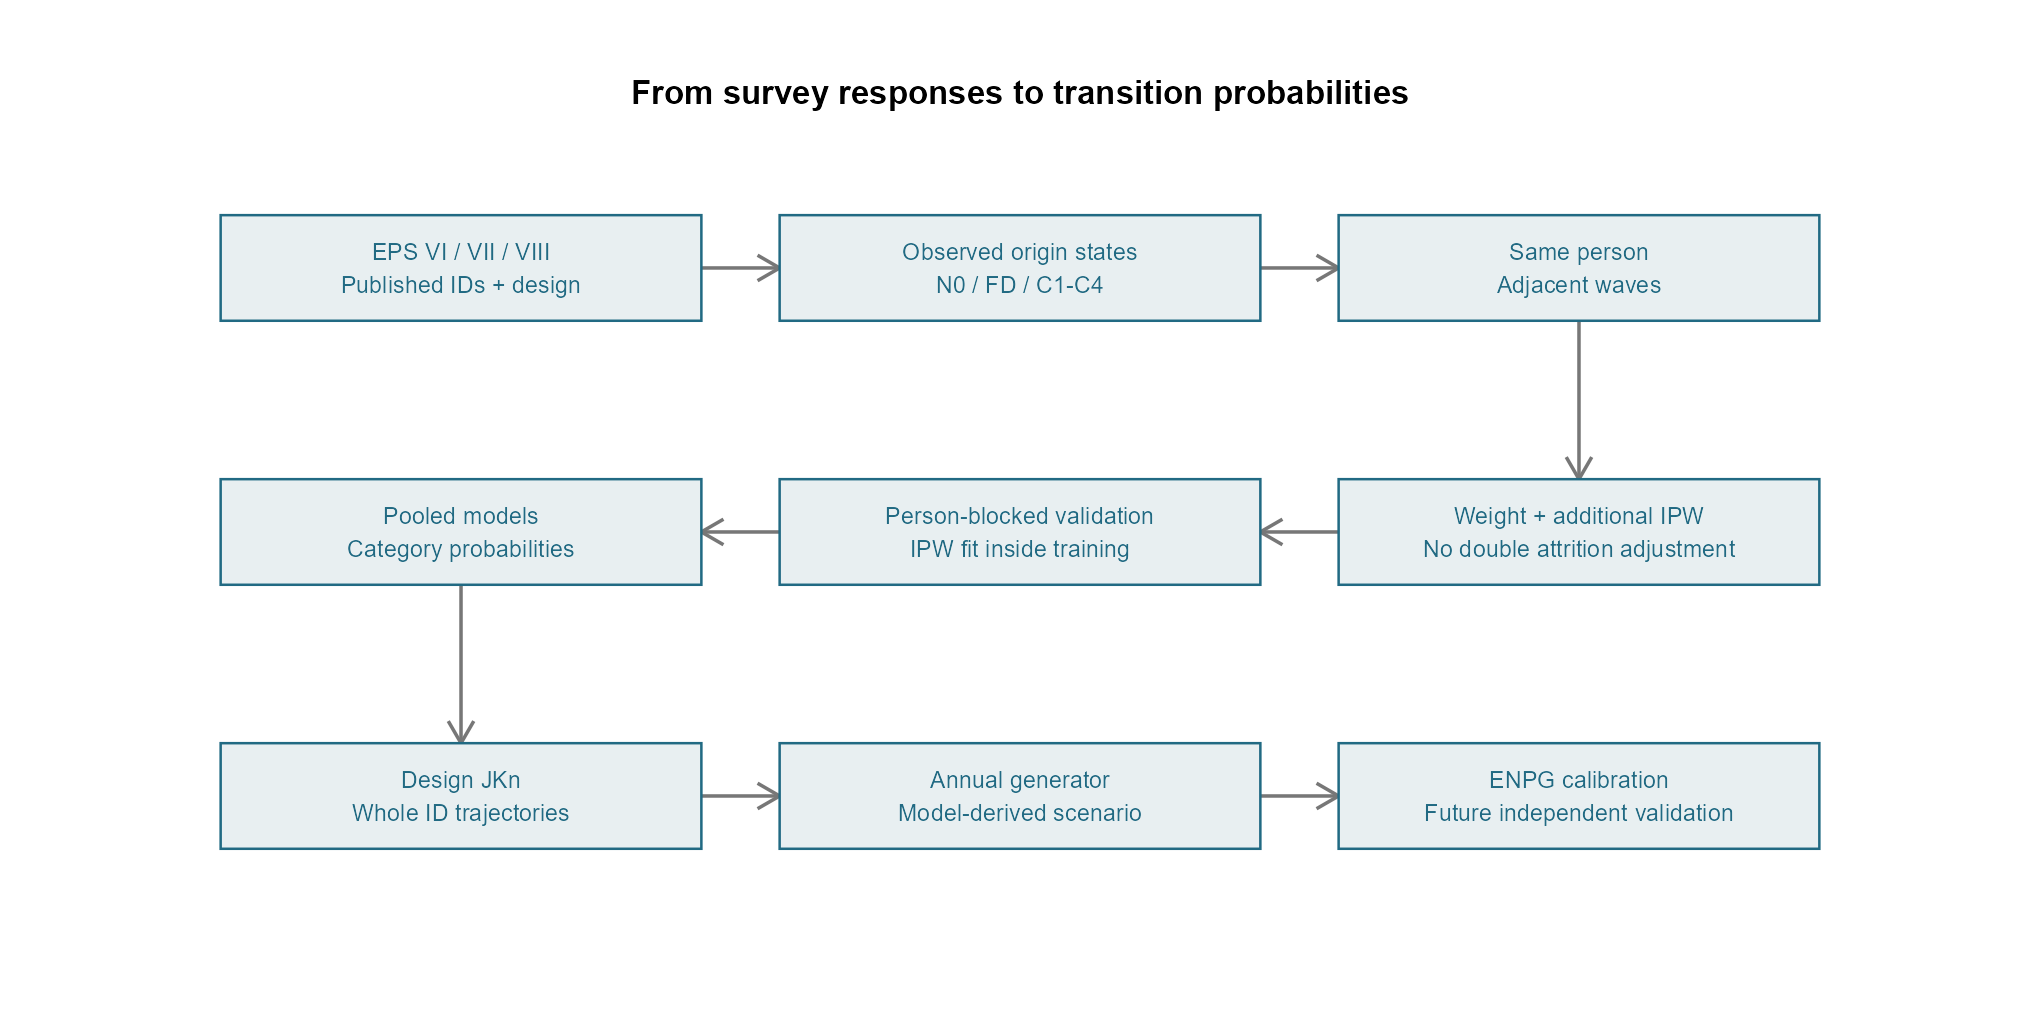

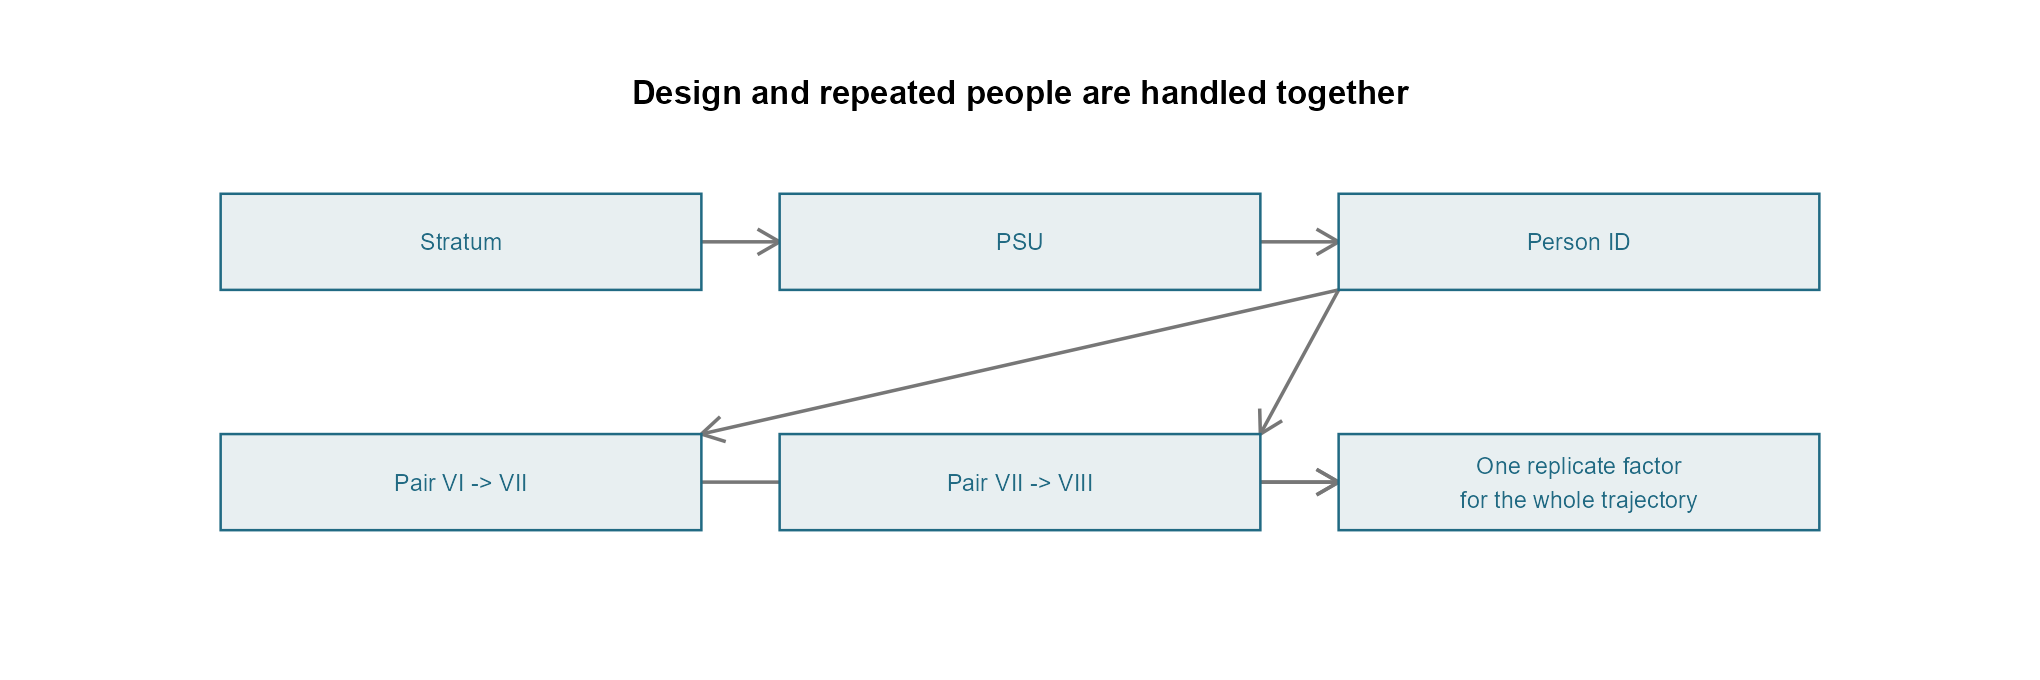

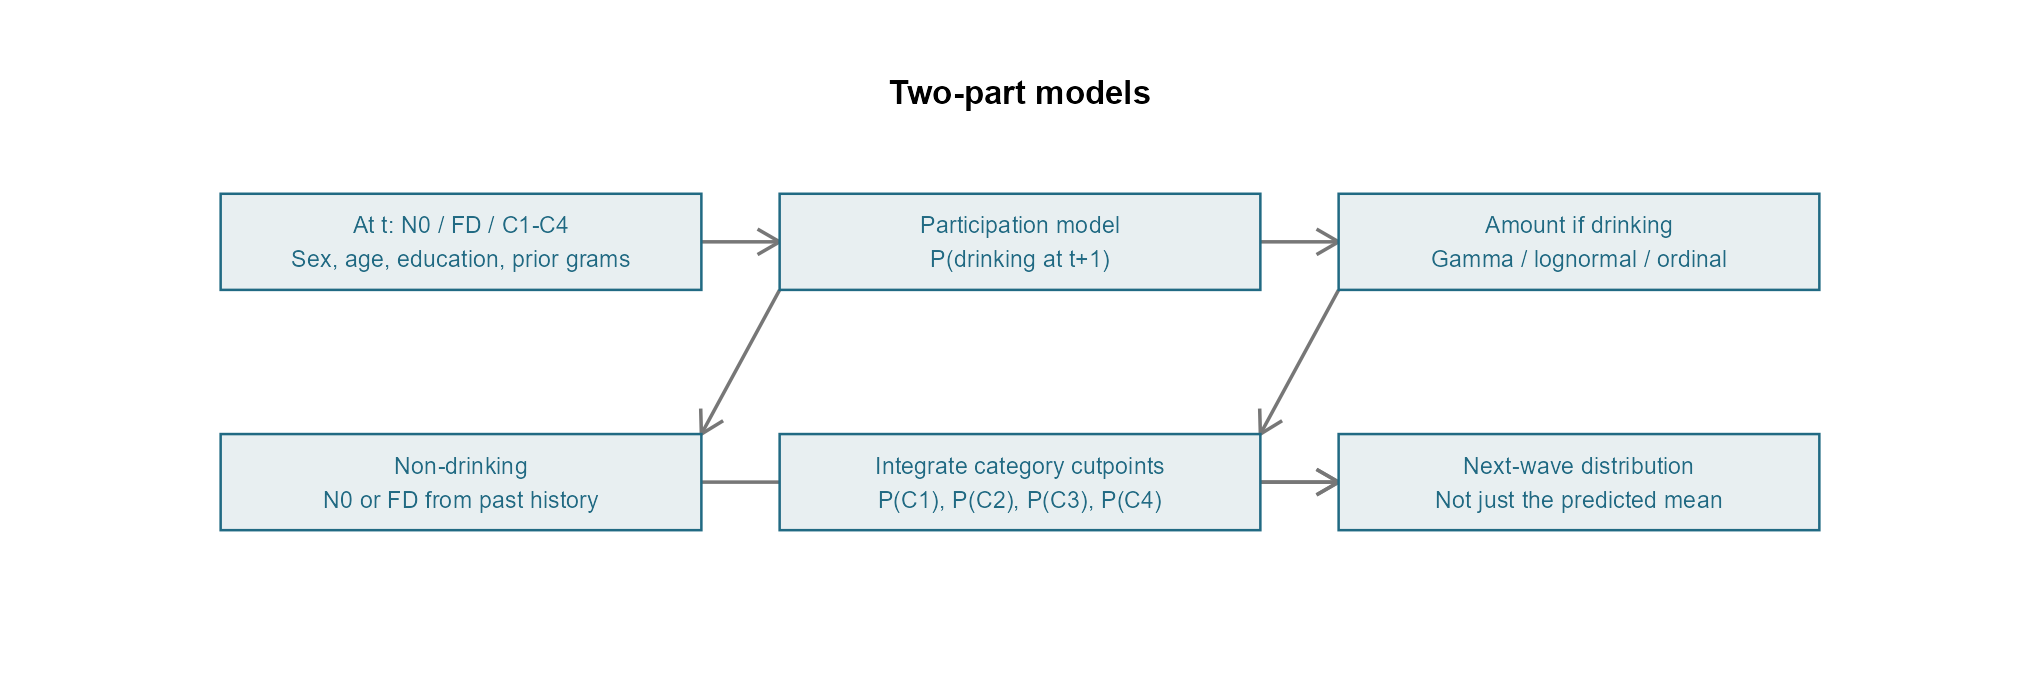

Elapsed: 0.05 minutes


In [3]:
#| label: eps-data-design
.t0 <- Sys.time()
ep_load()
ep_W <- ep_waves(12)
ep_risk <- ep_make_risk(ep_W)
ep_period_mass <- vapply(ep_periods,function(p) sum(ep_risk$period==p & ep_risk$complete),1)
names(ep_period_mass) <- ep_periods
ep_des <- ep_design()
ep_ip <- ep_ipw_fit(ep_risk)
ep_d <- ep_ipw_apply(ep_risk,ep_ip)
ep_check(nrow(ep_d)==length(unique(ep_d$row_id)),"One row per person and interval")
ep_check(all(ep_d$wn>0) && all(is.finite(ep_d$wn)),"Positive finite main weights")
ep_check(sum(ep_risk$longterm0)==0,"No fabricated strict long-term origin states")
ep_check(!any(ep_d$state0!="N0" & ep_d$state1=="N0") && !any(ep_d$state0=="N0" & ep_d$state1=="FD"),
 "Observed pairs respect the history-state transition map")
ep_counts <- as.data.frame(table(period=ep_d$period, sex=ep_d$sex, age_group=ep_d$age_group, state0=ep_d$state0))
names(ep_counts)[5] <- "n"
ep_save(ep_counts,"row_counts_state0_by_stratum")
ep_cohort <- do.call(rbind,lapply(ep_periods,function(p) {
 r<-ep_risk[ep_risk$period==p,]; d<-ep_d[ep_d$period==p,]
 data.frame(period=p, risk_set=nrow(r), usable_pairs=nrow(d), persons=length(unique(d$id)),
   age_min=min(d$age), age_max=max(d$age), weight_ESS=sum(d$wn)^2/sum(d$wn^2),
   main_weight=if(p=="VI_VII") "Official longitudinal + item/link-validity IPW" else "VII cross-sectional + follow-up/item IPW")
}))
ep_history_audit <- do.call(rbind,lapply(split(ep_W,ep_W$wave),function(d)
 data.frame(wave=d$wave[1], N0=sum(d$state=="N0",na.rm=TRUE), FD=sum(d$state=="FD",na.rm=TRUE),
  longterm_strict=sum(d$longterm), two_negative_proxy=sum(d$two_wave_negative))))
ep_design_audit <- data.frame(master_persons=nrow(ep_des$master),PSUs=length(unique(ep_des$master$psu)),
 strata=length(unique(ep_des$master$strata)), singleton_strata=sum(table(unique(ep_des$master[c("psu","strata")])$strata)==1),
 JKn_replicates=ncol(ep_des$multipliers), original_df=survey::degf(ep_des$survey), replicate_df=survey::degf(ep_des$replicate),
 known_VIII_deaths=sum(ep_W$wave=="VII_presencial" & ep_W$id %in% ep_dead8))
ep_save(ep_cohort,"cohort"); ep_save(ep_history_audit,"abstention_history_audit"); ep_save(ep_design_audit,"design_audit")
ep_save(as.data.frame(table(origin=ep_d$state0)),"origin_counts")
ep_show(ep_cohort,"Adjacent-wave analysis populations","Poblaciones de los pares consecutivos")
ep_show(data.frame(pairs=nrow(ep_d), persons=length(unique(ep_d$id)), persons_with_two_pairs=sum(table(ep_d$id)==2)),
 "Pairs and distinct people","Pares y personas distintas")
ep_show(ep_history_audit,"Past-only history flags; all available ages","Historia hasta cada entrevista; todas las edades disponibles")
ep_diagrams()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Weights, IPW and sampling design

**VI→VII:** the official longitudinal weight already adjusts participation. Additional IPW addresses only missing baseline/final classification and incompatible analytical links. **VII→VIII:** no pair-specific official longitudinal weight is available; VII cross-sectional weights are combined with follow-up/item-response IPW. Known VIII deaths are excluded. Survival is not completely observed among those lost to follow-up.

The pooled mixture fixes each period's relative contribution at its initial observed-pair count. This is an analytical mixture of two weighted populations, not a single national annual cohort. Observation probabilities have a 0.02 floor and completed weights are clipped at the 1st/99th percentiles. Thresholds are learned in training and applied to held-out data.

**Primary uncertainty:** stratified JKn using `cluster_ID` and `strata_ID`. Each replicate deletes/reweights a PSU, keeps all pairs of each ID together, and refits IPW and outcome models. Singleton strata use `survey.lonely.psu="adjust"`; their PSUs are not asserted to have certainty inclusion. The EPS report's `certainty` convention is a sensitivity.

JKn intervals use `survey` replication scales, centre on the full estimate and use a t reference with PSU-minus-strata degrees of freedom. **They are not bootstrap percentiles.** Probability intervals use a logit transformation; exact 0/1 boundaries use bounded normal limits. A **bootstrap with 1,000 replicates of complete person trajectories** is retained as a sensitivity, with IPW refitted. No second ID correction is added on top of JKn. A Markov assumption does not make one person's overlapping pairs independent.

This uses the published design but does not reconstruct stage-specific inclusion probabilities, FPCs or uncertainty in the official weights themselves. Kish ESS describes weight dispersion only; it does not multiply the confidence intervals.


In [4]:
#| label: eps-weight-audit
.t0 <- Sys.time()
ep_show(ep_design_audit,"Published design and replication","Diseño publicado y replicación")
ep_weight_audit <- do.call(rbind,lapply(split(ep_d,ep_d$period),function(d)
 data.frame(period=d$period[1], min_probability=min(d$p_obs),median_weight=stats::median(d$wn),max_weight=max(d$wn),
 clipped=sum(d$untrimmed!=d$wcorrected), weight_ESS=sum(d$wn)^2/sum(d$wn^2))))
ep_save(ep_weight_audit,"ipw_audit")
ep_singleton <- ep_taylor_sensitivity(); ep_save(ep_singleton,"singleton_convention_sensitivity")
ep_show(ep_weight_audit,"Weight diagnostics; ESS does not include clustering","Diagnóstico de pesos; ESS no incorpora conglomerados")
ep_show(ep_singleton,"Singleton sensitivity, descriptive fixed-IPW prevalence","Sensibilidad de estratos con una UPM; prevalencia con IPW fijo")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


master_persons,PSUs,strata,singleton_strata,JKn_replicates,original_df,replicate_df,known_VIII_deaths
7800,111,33,32,111,78,110,237


period,min_probability,median_weight,max_weight,clipped,weight_ESS
VI_VII,0.429,0.817,4.451,94,3153.580
VII_VIII,0.125,0.753,5.423,66,1932.492


singleton,weighted_current_destination,se_fixed_IPW,note
adjust,0.393,0.011,Descriptive fixed-IPW sensitivity; official certainty is a convention
certainty,0.393,0.010,Descriptive fixed-IPW sensitivity; official certainty is a convention


Elapsed: 0.00 minutes


## Models and fair comparison

**NC means current non-consumption: N0+FD.** Destination quantity is modelled in five categories, NC and C1–C4. Origin history then distinguishes N0 from FD among non-drinkers, yielding six-state matrices.

Matrices A provide the empirical reference with shrinkage: small cells borrow information from broader groups. Shrinkage strength is selected **inside training**. An education-stratified version is compared rather than assumed.

Gamma, lognormal, multinomial and ordinal models receive the same information: previous state and grams, sex, age, sex×age interaction, period and education. Two-part models share the participation equation. JRT is a **separate reference specification**, not a pure distribution-family comparison.

Gamma/lognormal predict a positive amount distribution. C1–C4 probabilities are obtained **by integrating between cutpoints**, not by classifying only the predicted mean. Dispersion uses normalized weights: multiplying weights by ten must leave predictions unchanged.

**Education:** compare no education, an ordinal effect, and its interactions with baseline drinking, sex and age. Coding 0/1/2 assumes equally spaced levels; it does not represent years of schooling. Missing education has a separate indicator. A multinomial amount model compares the ordinal with an option without proportional odds through held-out prediction, without a spurious composite-likelihood p-value.

Parametric models share information and support smooth extrapolation. This can help with C3/C4, but precision depends on the model's shape assumptions: **it does not create tail observations**. Multinomial regression is also parametric. Gamma/lognormal use continuous quantity and restrict its distribution; they can reduce variability at the cost of bias when that shape is incorrect. Greater efficiency is not automatic.


In [5]:
#| label: eps-model-validation
.t0 <- Sys.time()
ep_tunes <- list(ep_tune(ep_risk,FALSE),ep_tune(ep_risk,TRUE))
ep_k <- vapply(ep_tunes,function(x) x$k,1)
ep_save(rbind(ep_tunes[[1]]$scores,ep_tunes[[2]]$scores),"full_fit_shrinkage_tuning")
ep_fits <- lapply(stats::setNames(names(ep_models),names(ep_models)),function(nm) ep_fit(ep_d,nm,ep_k[if(nm=="A_education") 2 else 1]))
ep_scale_test <- lapply(c("Gamma","Lognormal","Multinomial","Ordinal_two_part"),function(nm) {
 d<-ep_d; d$wn<-10*d$wn
 diff<-max(abs(ep_prob(ep_fits[[nm]],ep_d)-ep_prob(ep_fit(d,nm,ep_k[1]),ep_d)))
 ep_check(diff<1e-7,paste("Weight-scale invariance",nm))
 data.frame(model=nm,max_absolute_difference=diff)
})
ep_save(do.call(rbind,ep_scale_test),"weight_scale_invariance")
ep_cv_result <- ep_cv(ep_risk)
ep_cvtab <- ep_cv_tables(ep_cv_result)
ep_contrasts <- ep_score_contrasts(ep_cvtab)
ep_save(ep_cv_result$audit,"CV_fold_audit"); ep_save(ep_cv_result$tuning,"CV_inner_tuning")
ep_save(ep_cvtab$scores,"CV_repeated_scores"); ep_save(ep_cvtab$summary,"cv_scores")
ep_save(ep_contrasts,"CV_paired_comparisons")
ep_show(ep_cvtab$summary,"Held-out category scores; lower log loss/Brier is better","Puntajes de categorías fuera de muestra; menor log loss/Brier es mejor",5)
ep_show(ep_contrasts[,1:8],"Paired comparisons; uncertainty uses PSU and strata","Comparaciones pareadas; incertidumbre con UPM y estratos",5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


CV repeat 1/3, fold 1/5 complete
CV repeat 1/3, fold 2/5 complete
CV repeat 1/3, fold 3/5 complete
CV repeat 1/3, fold 4/5 complete
CV repeat 1/3, fold 5/5 complete
CV repeat 2/3, fold 1/5 complete
CV repeat 2/3, fold 2/5 complete
CV repeat 2/3, fold 3/5 complete
CV repeat 2/3, fold 4/5 complete
CV repeat 2/3, fold 5/5 complete
CV repeat 3/3, fold 1/5 complete
CV repeat 3/3, fold 2/5 complete
CV repeat 3/3, fold 3/5 complete
CV repeat 3/3, fold 4/5 complete
CV repeat 3/3, fold 5/5 complete


model,logloss,brier,accuracy
Lognormal,0.70664,0.41663,0.69454
Lognormal_education_interaction,0.70729,0.41669,0.69408
Ordinal_single,0.70882,0.41685,0.69460
NonPO_two_part,0.70943,0.41700,0.69394
Multinomial,0.70952,0.41707,0.69344
Ordinal_two_part,0.71126,0.41699,0.69381
A,0.71605,0.42156,0.69237
A_education,0.71720,0.42188,0.69438
Gamma,0.71866,0.41679,0.69435
Gamma_no_education,0.71992,0.41762,0.69515


model,reference,difference,se_design,lower,upper,relative_geometric_probability_gain_pct,mean_absolute_class_probability_change_pp
Lognormal,Gamma,-0.01203,0.00344,-0.01889,-0.00517,1.21013,0.35211
Gamma,A,0.00262,0.00527,-0.00788,0.01311,-0.26119,2.12367
Lognormal,A,-0.00941,0.00302,-0.01542,-0.00341,0.94577,2.07075
NonPO_two_part,Ordinal_two_part,-0.00182,0.00274,-0.00727,0.00363,0.18246,0.28949
Ordinal_two_part,Gamma,-0.00741,0.00506,-0.01748,0.00266,0.74373,0.38596
Ordinal_single,Gamma,-0.00984,0.00479,-0.01938,-0.00030,0.98899,0.82632
Multinomial,Gamma,-0.00914,0.00415,-0.01741,-0.00087,0.91829,0.50147
A_education,A,0.00115,0.00096,-0.00077,0.00307,-0.11491,0.62142
Gamma,Gamma_no_education,-0.00125,0.00109,-0.00342,0.00092,0.12521,0.83684
Gamma_education_interaction,Gamma,0.00166,0.00109,-0.00051,0.00383,-0.16593,0.58470


Elapsed: 1.65 minutes


## Which model wins, and by how much?

The preceding table is recomputed: **the old version's ranking is not retained**. Validation uses five person-blocked folds, three repeated partitions, and IPW learned without the held-out people. Matrix A selects shrinkage in three inner folds.

Paired log loss is model minus reference: negative favours the first model. If the interval crosses zero, this evaluation does not clearly distinguish their scores. The relative change in geometric probability assigned to observed categories and mean change in class probabilities, in percentage points, quantify the size of small score differences. No clinical equivalence margin is invented.

Score intervals use PSU/strata but are **conditional on already-trained predictions**. Three repetitions show partition sensitivity, not three independent studies. Decisions should consider calibration and tails as well as overall scores.

The lowest average score identifies the leading candidate in this comparison. It does not establish superiority over every competitor: the reported paired contrasts do not cover every model pair. A detectable advantage over Gamma can still be small in practical terms.


In [6]:
#| label: eps-calibration
.t0 <- Sys.time()
ep_cal <- do.call(rbind,lapply(c("A","Gamma","Lognormal","Ordinal_two_part"),function(nm) {
 P<-ep_cvtab$prob[[nm]]
 data.frame(model=nm,category=ep_Y,
  observed=vapply(ep_Y,function(s) stats::weighted.mean(ep_d$y1==s,ep_cvtab$w),1),
  predicted=colSums(P*ep_cvtab$w)/sum(ep_cvtab$w))
}))
ep_save(ep_cal,"calibration_destination")
ep_show(ep_cal,"Held-out observed and predicted shares","Proporciones observadas y predichas fuera de muestra",4)
ep_model_answer <- data.frame(best_logloss=ep_cvtab$summary$model[1],
 best_brier=ep_cvtab$summary$model[which.min(ep_cvtab$summary$brier)],
 lognormal_minus_gamma=ep_contrasts$difference[1],lower=ep_contrasts$lower[1],upper=ep_contrasts$upper[1],
 clear_gamma_lognormal_separation=ep_contrasts$lower[1]>0 | ep_contrasts$upper[1]<0)
ep_save(ep_model_answer,"model_decision_summary"); ep_show(ep_model_answer,"Current result, not a predetermined winner","Resultado actual, sin ganador predeterminado",5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,category,observed,predicted
A,NC,0.6065,0.6035
A,C1,0.3604,0.3628
A,C2,0.0187,0.0189
A,C3,0.0096,0.0098
A,C4,0.0048,0.0049
Gamma,NC,0.6065,0.6063
Gamma,C1,0.3604,0.3628
Gamma,C2,0.0187,0.0227
Gamma,C3,0.0096,0.0070
Gamma,C4,0.0048,0.0012


best_logloss,best_brier,lognormal_minus_gamma,lower,upper,clear_gamma_lognormal_separation
Lognormal,Lognormal,-0.01203,-0.01889,-0.00517,TRUE


Elapsed: 0.00 minutes


## Matrices, confidence intervals and exported parameters

Each row averages predictions **among people actually observed in that origin**, retaining their previous grams and education. Previous quantity is no longer replaced by a synthetic median. Rows without people are NA; structural impossibility is distinct from an unobserved row.

JKn refits outcome models and IPW. Selected shrinkage and model family remain fixed, so intervals are conditional on those choices. If an origin disappears in a replicate, it is reported without fabricating an interval. Gamma/lognormal coefficient SEs use replication rather than ordinary `summary(glm)` output.


In [7]:
#| label: eps-design-inference
.t0 <- Sys.time()
ep_points <- ep_targets(ep_d,ep_fits[ep_main_models])
ep_pool_tab <- do.call(rbind,lapply(c("A","Gamma","Lognormal"),function(nm) {
 d<-ep_d; d$pooled<-"All"
 ep_matrices(d,ep_prob(ep_fits[[nm]],d),nm,by="pooled")
}))
ep_jk <- ep_jackknife()
ep_jkmat <- do.call(rbind,lapply(ep_jk,function(x) x$target[names(ep_vector(ep_points))]))
ep_ci <- cbind(ep_points,ep_interval(ep_vector(ep_points),ep_jkmat))
ep_save(ep_ci,"transition_matrices_design_CI")
ep_engine <- ep_coef(ep_fits)
ep_coef_names <- paste(ep_engine$model,ep_engine$component,ep_engine$term,sep="::")
ep_engine <- cbind(ep_engine,ep_interval(ep_engine$estimate,do.call(rbind,lapply(ep_jk,function(x) x$coefficients[ep_coef_names])),probability=FALSE))
ep_save(ep_engine,"engine_coefficients_design_CI")
ep_show(ep_ci[ep_ci$model=="Gamma" & ep_ci$from=="C1" & ep_ci$to=="C1",c("period","sex","age_group","n_origin","estimate","lower","upper")],
 "Example: remaining in C1, Gamma model","Ejemplo: permanecer en C1, modelo Gamma")
ep_person <- ep_bootstrap_person()
ep_personmat <- do.call(rbind,lapply(ep_person,function(x) x$target))
ep_perpoint <- ep_points[ep_points$model %in% c("Gamma","Lognormal"),]
ep_person_ci <- cbind(ep_perpoint,ep_interval(ep_vector(ep_perpoint),ep_personmat,"person"))
ep_save(ep_person_ci,"transition_matrices_person_CI")
ep_mc <- do.call(rbind,lapply(c(100,250,500,1000),function(B) {
 s<-apply(ep_personmat[seq_len(B),,drop=FALSE],2,stats::sd)
 ref<-apply(ep_personmat,2,stats::sd); good<-is.finite(s)&is.finite(ref)&ref>0
 data.frame(replicates=B,median_SE_ratio_to_1000=stats::median(s[good]/ref[good]),
  p90_absolute_relative_difference=as.numeric(stats::quantile(abs(s[good]/ref[good]-1),.9)))
}))
ep_save(ep_mc,"bootstrap_stability"); ep_show(ep_mc,"Bootstrap stability; 1,000 whole-person replicas","Estabilidad del bootstrap; 1.000 réplicas por persona")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


EPS design JKn 10/111
EPS design JKn 20/111
EPS design JKn 30/111
EPS design JKn 40/111
EPS design JKn 50/111
EPS design JKn 60/111
EPS design JKn 70/111
EPS design JKn 80/111
EPS design JKn 90/111
EPS design JKn 100/111
EPS design JKn 110/111
EPS design JKn 111/111


period,sex,age_group,n_origin,estimate,lower,upper
VI_VII,Men,18-29,428,0.671,0.621,0.717
VI_VII,Men,30-44,165,0.665,0.605,0.720
VI_VII,Men,45-59,259,0.615,0.560,0.668
VI_VII,Men,60-65,92,0.601,0.506,0.689
VI_VII,Women,18-29,310,0.545,0.500,0.589
VI_VII,Women,30-44,127,0.471,0.406,0.537
VI_VII,Women,45-59,195,0.400,0.345,0.457
VI_VII,Women,60-65,61,0.410,0.337,0.487
VII_VIII,Men,18-29,150,0.626,0.566,0.683
VII_VIII,Men,30-44,137,0.603,0.547,0.657


Person bootstrap 100/1000; IPW refitted
Person bootstrap 200/1000; IPW refitted
Person bootstrap 300/1000; IPW refitted
Person bootstrap 400/1000; IPW refitted
Person bootstrap 500/1000; IPW refitted
Person bootstrap 600/1000; IPW refitted
Person bootstrap 700/1000; IPW refitted
Person bootstrap 800/1000; IPW refitted
Person bootstrap 900/1000; IPW refitted
Person bootstrap 1000/1000; IPW refitted


replicates,median_SE_ratio_to_1000,p90_absolute_relative_difference
100,0.985,0.143
250,0.987,0.076
500,0.999,0.054
1000,1.000,0.000


Elapsed: 18.53 minutes


## Transport, earlier history and rank matching

Both **period directions** are evaluated while always predicting forward within a pair: train VI→VII/test VII→VIII, and train VII→VIII/test VI→VII. All test persons are excluded from training; ages are restricted to common support 23–65; unsupported FD origins are reported. FD is never silently recoded to N0.

**Alcohol validation in V/2012 is not feasible with the delivered files.** Its 21 databases contain no alcohol variables/labels; the supplied RAR contains documentation, not additional alcohol variables. The official dossier (p. 23) also advises against statistical inference with that round. Reconstructing V would be an unvalidated scenario rather than observed reverse-period transport.

The history analysis compares models adjusted for current state and grams, sex, age and education, **with and without VI history**. It is repeated with education interactions and restricted to complete three-wave histories. Chapman–Kolmogorov is a marginal composition diagnostic without a formal “Markov rejection” p-value.

To isolate rank matching, the benchmark uses **the same people, weights, baseline groups and endpoint margins** as the observed panel. Only individual association is replaced by rank coupling. Persistence can increase by construction even when margins match exactly.


In [8]:
#| label: eps-transport-history
.t0 <- Sys.time()
ep_trans <- ep_transport(); ep_save(ep_trans$scores,"transport_scores");ep_save(ep_trans$coverage,"transport_support")
ep_transport_summary <- do.call(rbind,lapply(split(ep_trans$scores,paste(ep_trans$scores$direction,ep_trans$scores$model)),function(z)
 data.frame(direction=z$direction[1],model=z$model[1],logloss=stats::weighted.mean(z$logloss,z$weight_sum),
  brier=stats::weighted.mean(z$brier,z$weight_sum),n=sum(z$n))))
ep_save(ep_transport_summary,"transport_summary")
ep_show(ep_transport_summary,
 "Person-disjoint forward and reverse-period transport","Transporte y retrotransporte sin compartir personas",4)
ep_hist <- ep_history_check(); ep_save(ep_hist,"adjusted_history_validation")
ep_show(ep_hist,"Does earlier history add predictive information after adjustment?","¿La historia anterior aporta información después del ajuste?",5)
ep_ck_tab <- ep_ck();ep_save(ep_ck_tab,"chapman_kolmogorov_descriptive")
ep_rank_tab <- ep_rank(ep_d);ep_save(ep_rank_tab,"rank_matching_vs_panel")
ep_show(ep_rank_tab[ep_rank_tab$from=="C1" & ep_rank_tab$to=="C1",],
 "C1 persistence: matched margins, different dependence","Permanencia en C1: mismas marginales, distinta dependencia",3)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


direction,model,logloss,brier,n
forward,A,0.6713,0.3960,2943
forward,Gamma,0.6736,0.3975,2943
forward,JRT_reference,0.6728,0.3986,2943
forward,Lognormal,0.6619,0.3971,2943
forward,Multinomial,0.6697,0.3976,2943
forward,Ordinal_single,0.6643,0.3960,2943
forward,Ordinal_two_part,0.6899,0.3972,2943
retro,A,0.7956,0.4460,3908
retro,Gamma,0.8484,0.4459,3908
retro,JRT_reference,0.7889,0.4485,3908


model,n_persons,difference_history_minus_current,lower,upper,population
Gamma,2730,0.00464,-0.00444,0.01372,complete three-wave histories; conditional OOF comparison
Gamma_education_interaction,2730,0.00405,-0.00494,0.01305,complete three-wave histories; conditional OOF comparison


period,source,from,to,probability
VI_VII,Observed_panel,C1,C1,0.583
VI_VII,Rank_matching,C1,C1,0.940
VII_VIII,Observed_panel,C1,C1,0.523
VII_VIII,Rank_matching,C1,C1,0.774


Elapsed: 0.28 minutes


## Annual probabilities: an additional modelling layer

A common continuous-time generator is fitted to both intervals, with nonnegative off-diagonal rates:

$$P(\Delta)=\exp(Q\Delta),\qquad P(1)=\exp(Q).$$

Time-homogeneous rates are an assumption. Annualization does not turn an observed four-year interval into observed one-year transitions. Starting values and penalties are compared; row sums and composition under the same generator are checked. Annual estimates are **pooled**, without claiming separate age/sex generators are identified for C4. Confidence intervals refit the generator in each JKn replicate, conditional on its fixed penalty.

These matrices are candidates for ENPG calibration. A simulation that changes covariates or rates with age needs additional trajectory validation; the matrix identity checked here does not validate that full engine.

**Stability:** the sensitivity table compares the primary fit with multiple restarts and penalties. Nearly equal objectives can yield different annual probabilities. Intervals condition on the primary initialization and penalty and do not cover this entire ambiguity. The opening summary reports its observed magnitude. Large differences keep this layer exploratory, with between-wave probabilities remaining the primary result.

**Observed and latent history:** annual fitting compares N0+FD with the observed non-drinking destination. It can represent an unobserved N0→drinking→FD path between interviews. Annual FD therefore includes model-imputed drinking history, whereas survey-wave FD requires observed previous drinking. This distinction depends on assumptions and is not identified by the collapsed destinations.


In [9]:
#| label: eps-annual-layer
.t0 <- Sys.time()
ep_annual_full <- lapply(ep_fits[c("A","Gamma","Lognormal")],function(f) ep_annual(ep_d,f,starts=.05,check_gradient=TRUE))
ep_ann_point <- unlist(lapply(ep_annual_full,function(x) as.vector(x$P)))
ep_ann_rep <- do.call(rbind,lapply(ep_jk,function(x) x$annual))
ep_ann <- do.call(rbind,lapply(names(ep_annual_full),function(nm) {
 z<-ep_annual_full[[nm]]
 ep_check(max(abs(rowSums(z$P)-1))<1e-8 && min(z$P)>-1e-10,paste("Annual stochastic matrix",nm))
 ep_check(z$semigroup_error<1e-8,paste("Annual semigroup",nm))
 data.frame(model=nm,from=rep(ep_ST,6),to=rep(ep_ST,each=6),estimate=as.vector(z$P),
  weighted_reconstruction_RMSE=z$rmse,optimizer_code=z$convergence,semigroup_error=z$semigroup_error)
}))
ep_ann <- cbind(ep_ann,ep_interval(ep_ann_point,ep_ann_rep))
ep_save(ep_ann,"annual_pooled_matrices_design_CI")
ep_ann_sens <- do.call(rbind,lapply(c(1e-5,5e-5,2e-4),function(pen) {
 z<-ep_annual(ep_d,ep_fits$Gamma,lambda=pen)
 data.frame(penalty=pen,weighted_reconstruction_RMSE=z$rmse,
  start_objective_range=z$start_objective_range,max_annual_difference=max(abs(z$P-ep_annual_full$Gamma$P)),
  optimizer_code=z$convergence)
}))
ep_save(ep_ann_sens,"annual_generator_sensitivity")
ep_show(ep_ann[ep_ann$model=="Gamma" & ep_ann$from==ep_ann$to,],
 "Annual staying probabilities: model-derived, pooled Gamma","Permanencia anual: resultado modelado, Gamma agrupado")
ep_show(ep_ann_sens,"Annual reconstruction sensitivity","Sensibilidad de reconstrucción anual",5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,from,to,estimate,weighted_reconstruction_RMSE,optimizer_code,semigroup_error,se,lower,upper,valid_replicates,interval_status
Gamma,N0,N0,0.911,0.063,0,0,0.005,0.901,0.921,111,available
Gamma,FD,FD,0.871,0.063,0,0,0.020,0.827,0.905,111,available
Gamma,C1,C1,0.811,0.063,0,0,0.012,0.786,0.834,111,available
Gamma,C2,C2,0.519,0.063,0,0,0.049,0.421,0.615,111,available
Gamma,C3,C3,0.420,0.063,0,0,0.091,0.257,0.604,111,available
Gamma,C4,C4,0.089,0.063,0,0,0.862,0.000,1.000,111,available


penalty,weighted_reconstruction_RMSE,start_objective_range,max_annual_difference,optimizer_code
0.00001,0.06276,0.00002,0.27896,0
0.00005,0.06322,0.00000,0.07927,0
0.00020,0.06404,0.00000,0.03928,0


Elapsed: 0.04 minutes


## Conversion, alternative weights and high typical quantity

Gamma and lognormal are refitted at 12 and 15.7 g/drink. Their difference measures classification sensitivity; it does not validate drink size on its own. Base weights are also compared with IPW-corrected weights, retaining VI→VII's longitudinal-weight purpose; the VI–VII–VIII weight is not treated as pair-specific VII→VIII weighting.

The typical-quantity signal **≥5 drinks for men / ≥4 for women**, in any beverage, remains separate. It is not observed ENPG 30-day HED. Missing beverage quantity is not treated as absence of the signal. Its regression uses EPS design, although descriptive intervals condition on estimated IPW; it is not a main volume predictor or an export of validated HED.


grams_per_drink,model,quantity,probability
12.0,Gamma,Drinking_t1,0.3932
12.0,Gamma,Escalation_from_C1,0.0550
12.0,Gamma,C3_C4_t1,0.0081
12.0,Lognormal,Drinking_t1,0.3932
12.0,Lognormal,Escalation_from_C1,0.0498
12.0,Lognormal,C3_C4_t1,0.0108
15.7,Gamma,Drinking_t1,0.3932
15.7,Gamma,Escalation_from_C1,0.0893
15.7,Gamma,C3_C4_t1,0.0179
15.7,Lognormal,Drinking_t1,0.3932


scenario,current_t1,C3_C4_t1
base_only,0.3870,0.0076
base_plus_IPW,0.3932,0.0081


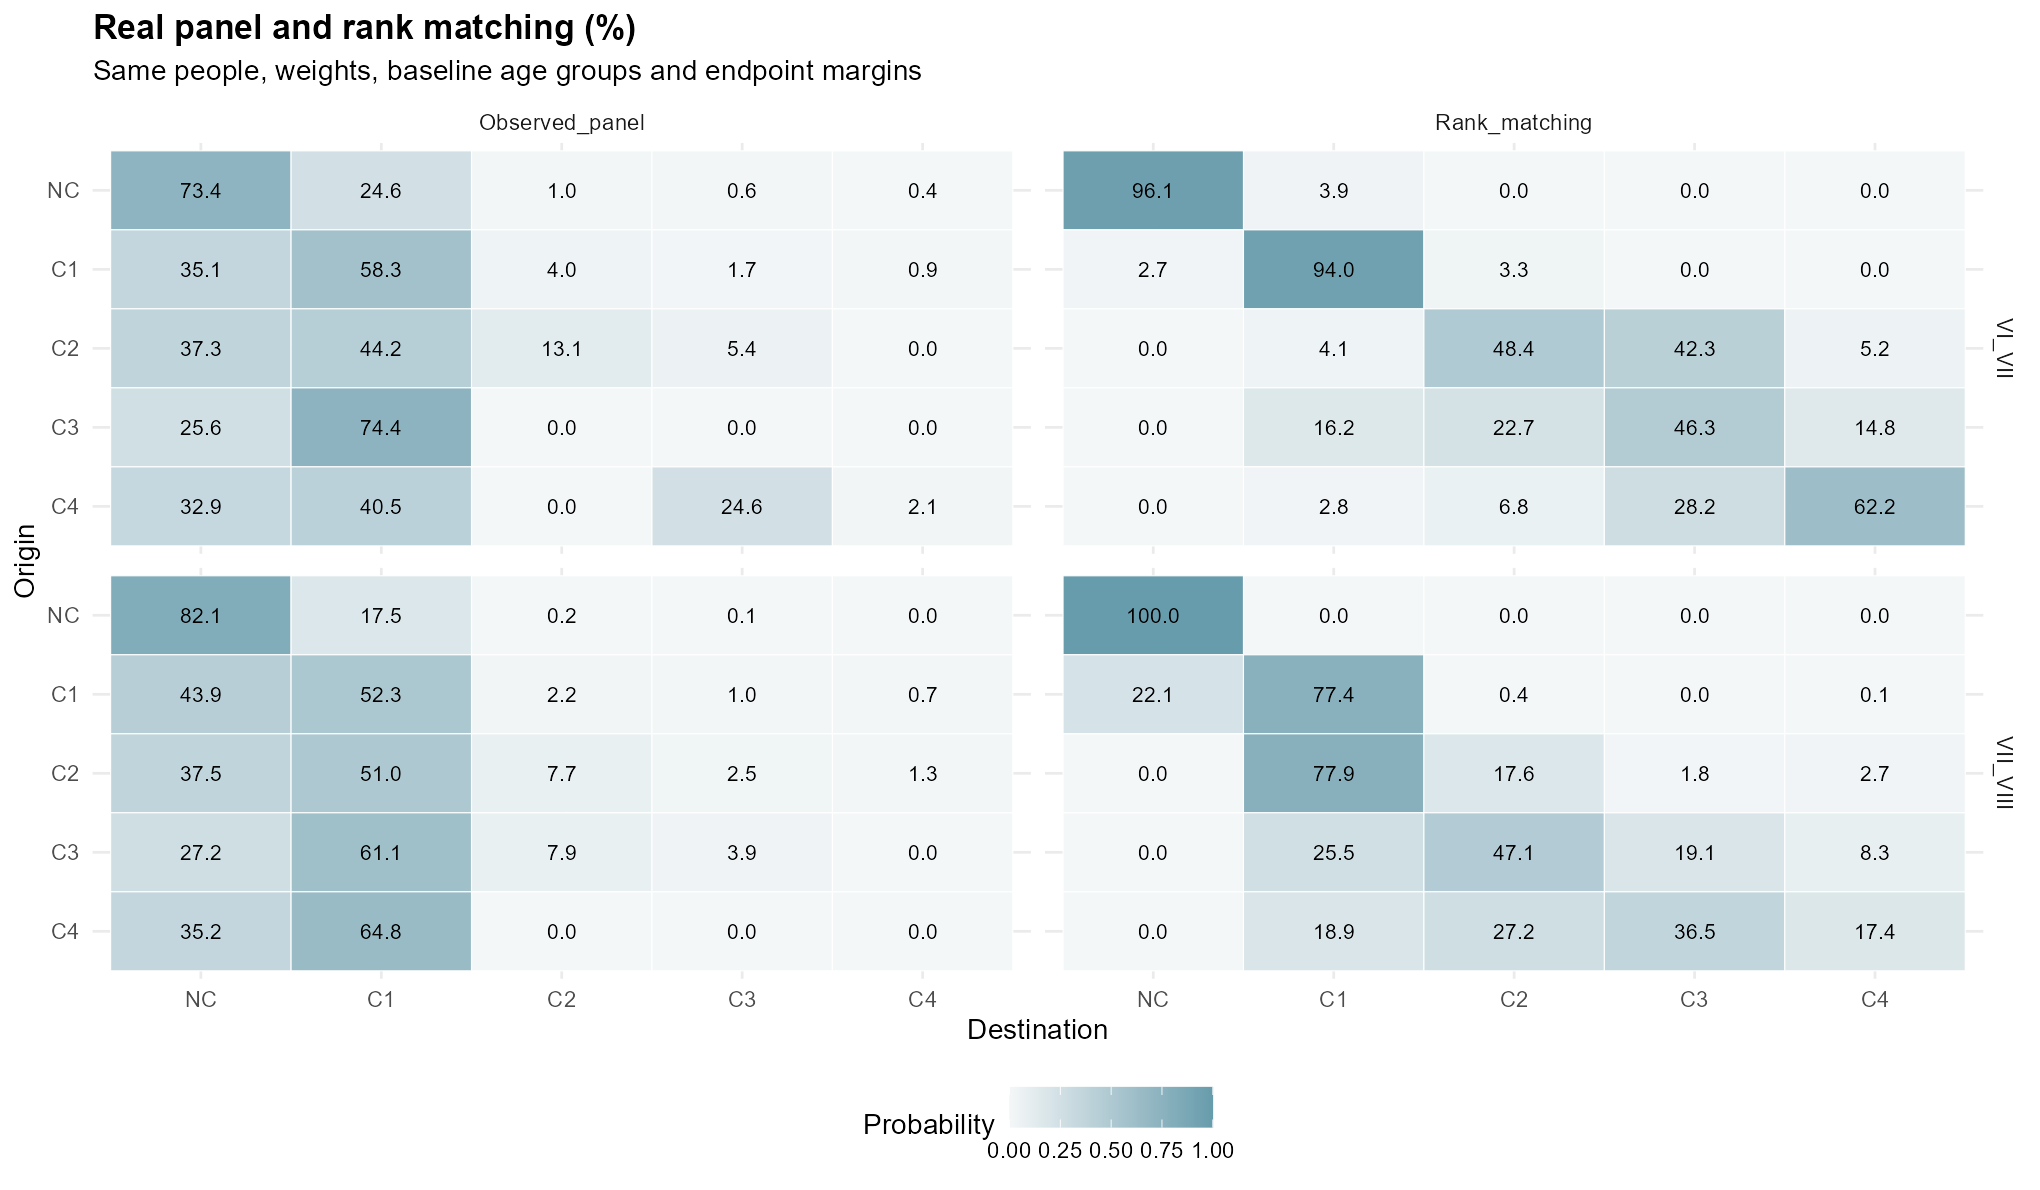

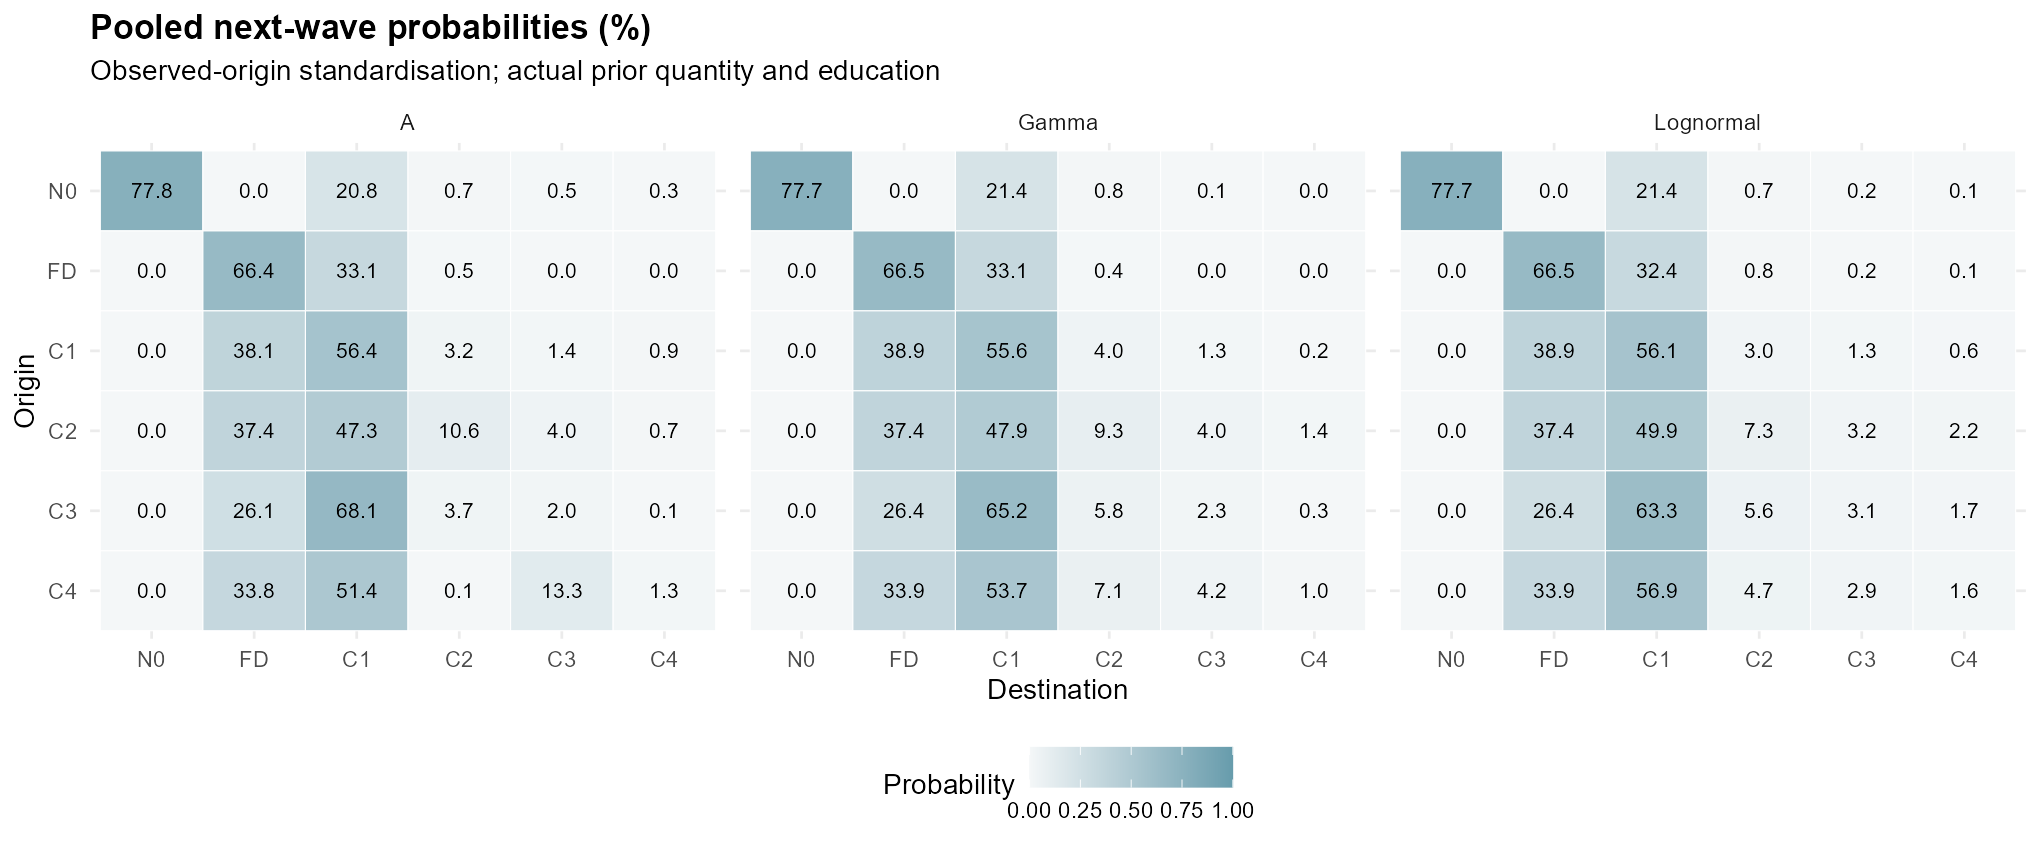

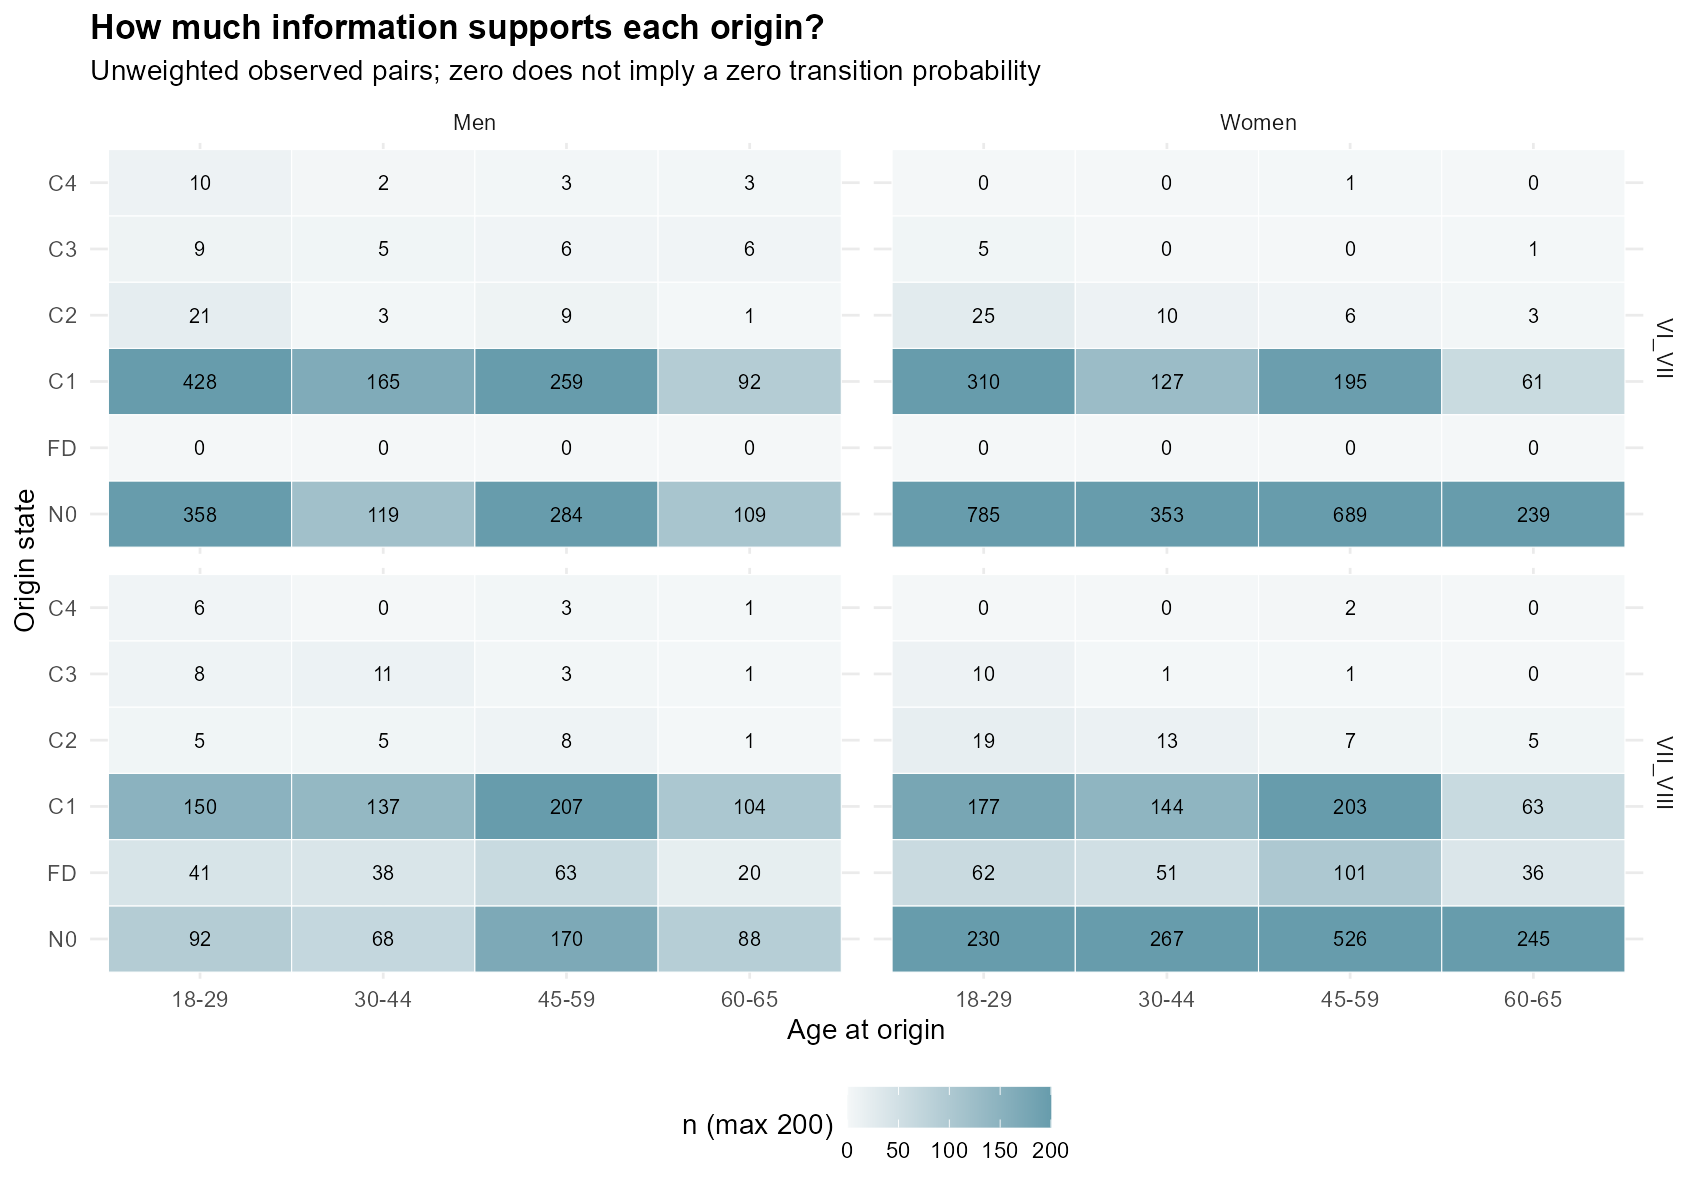

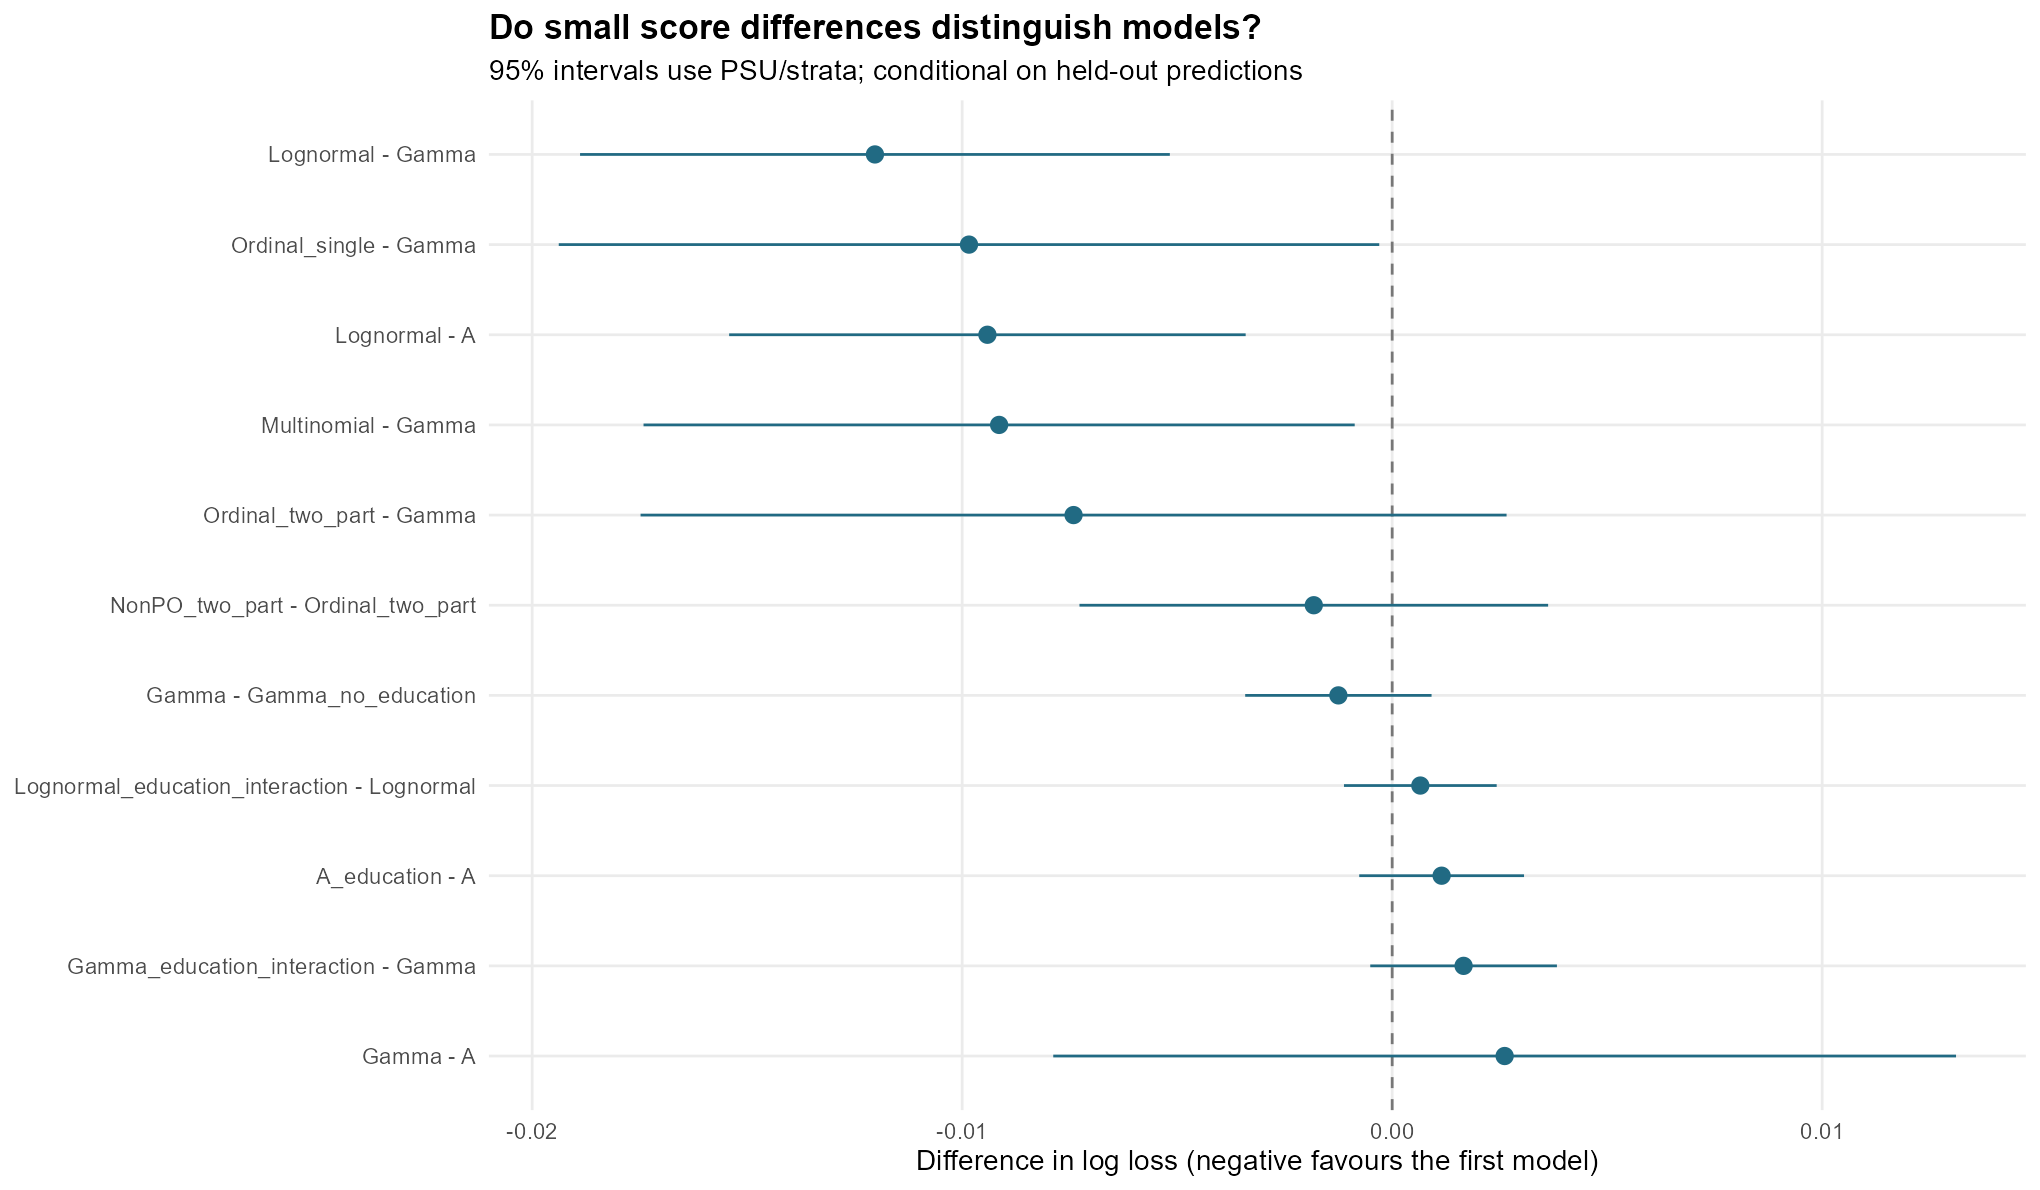

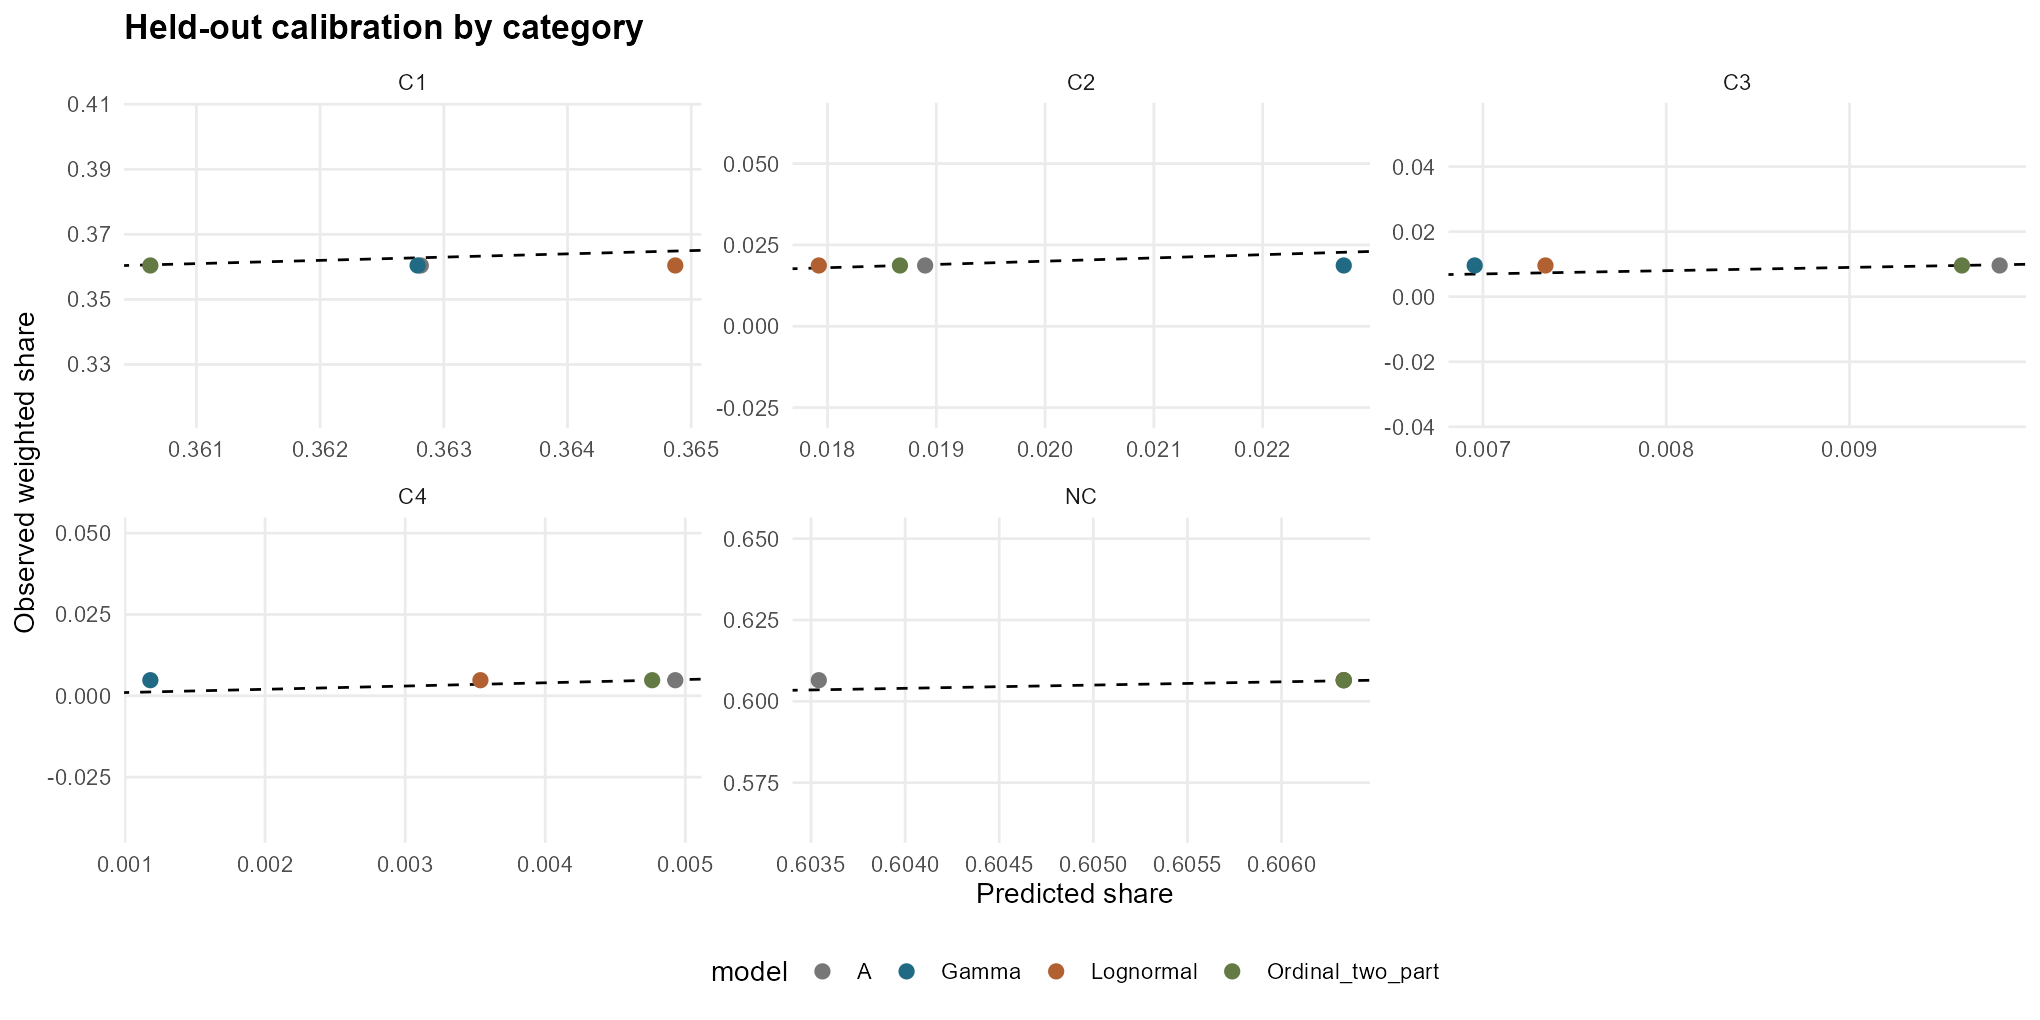

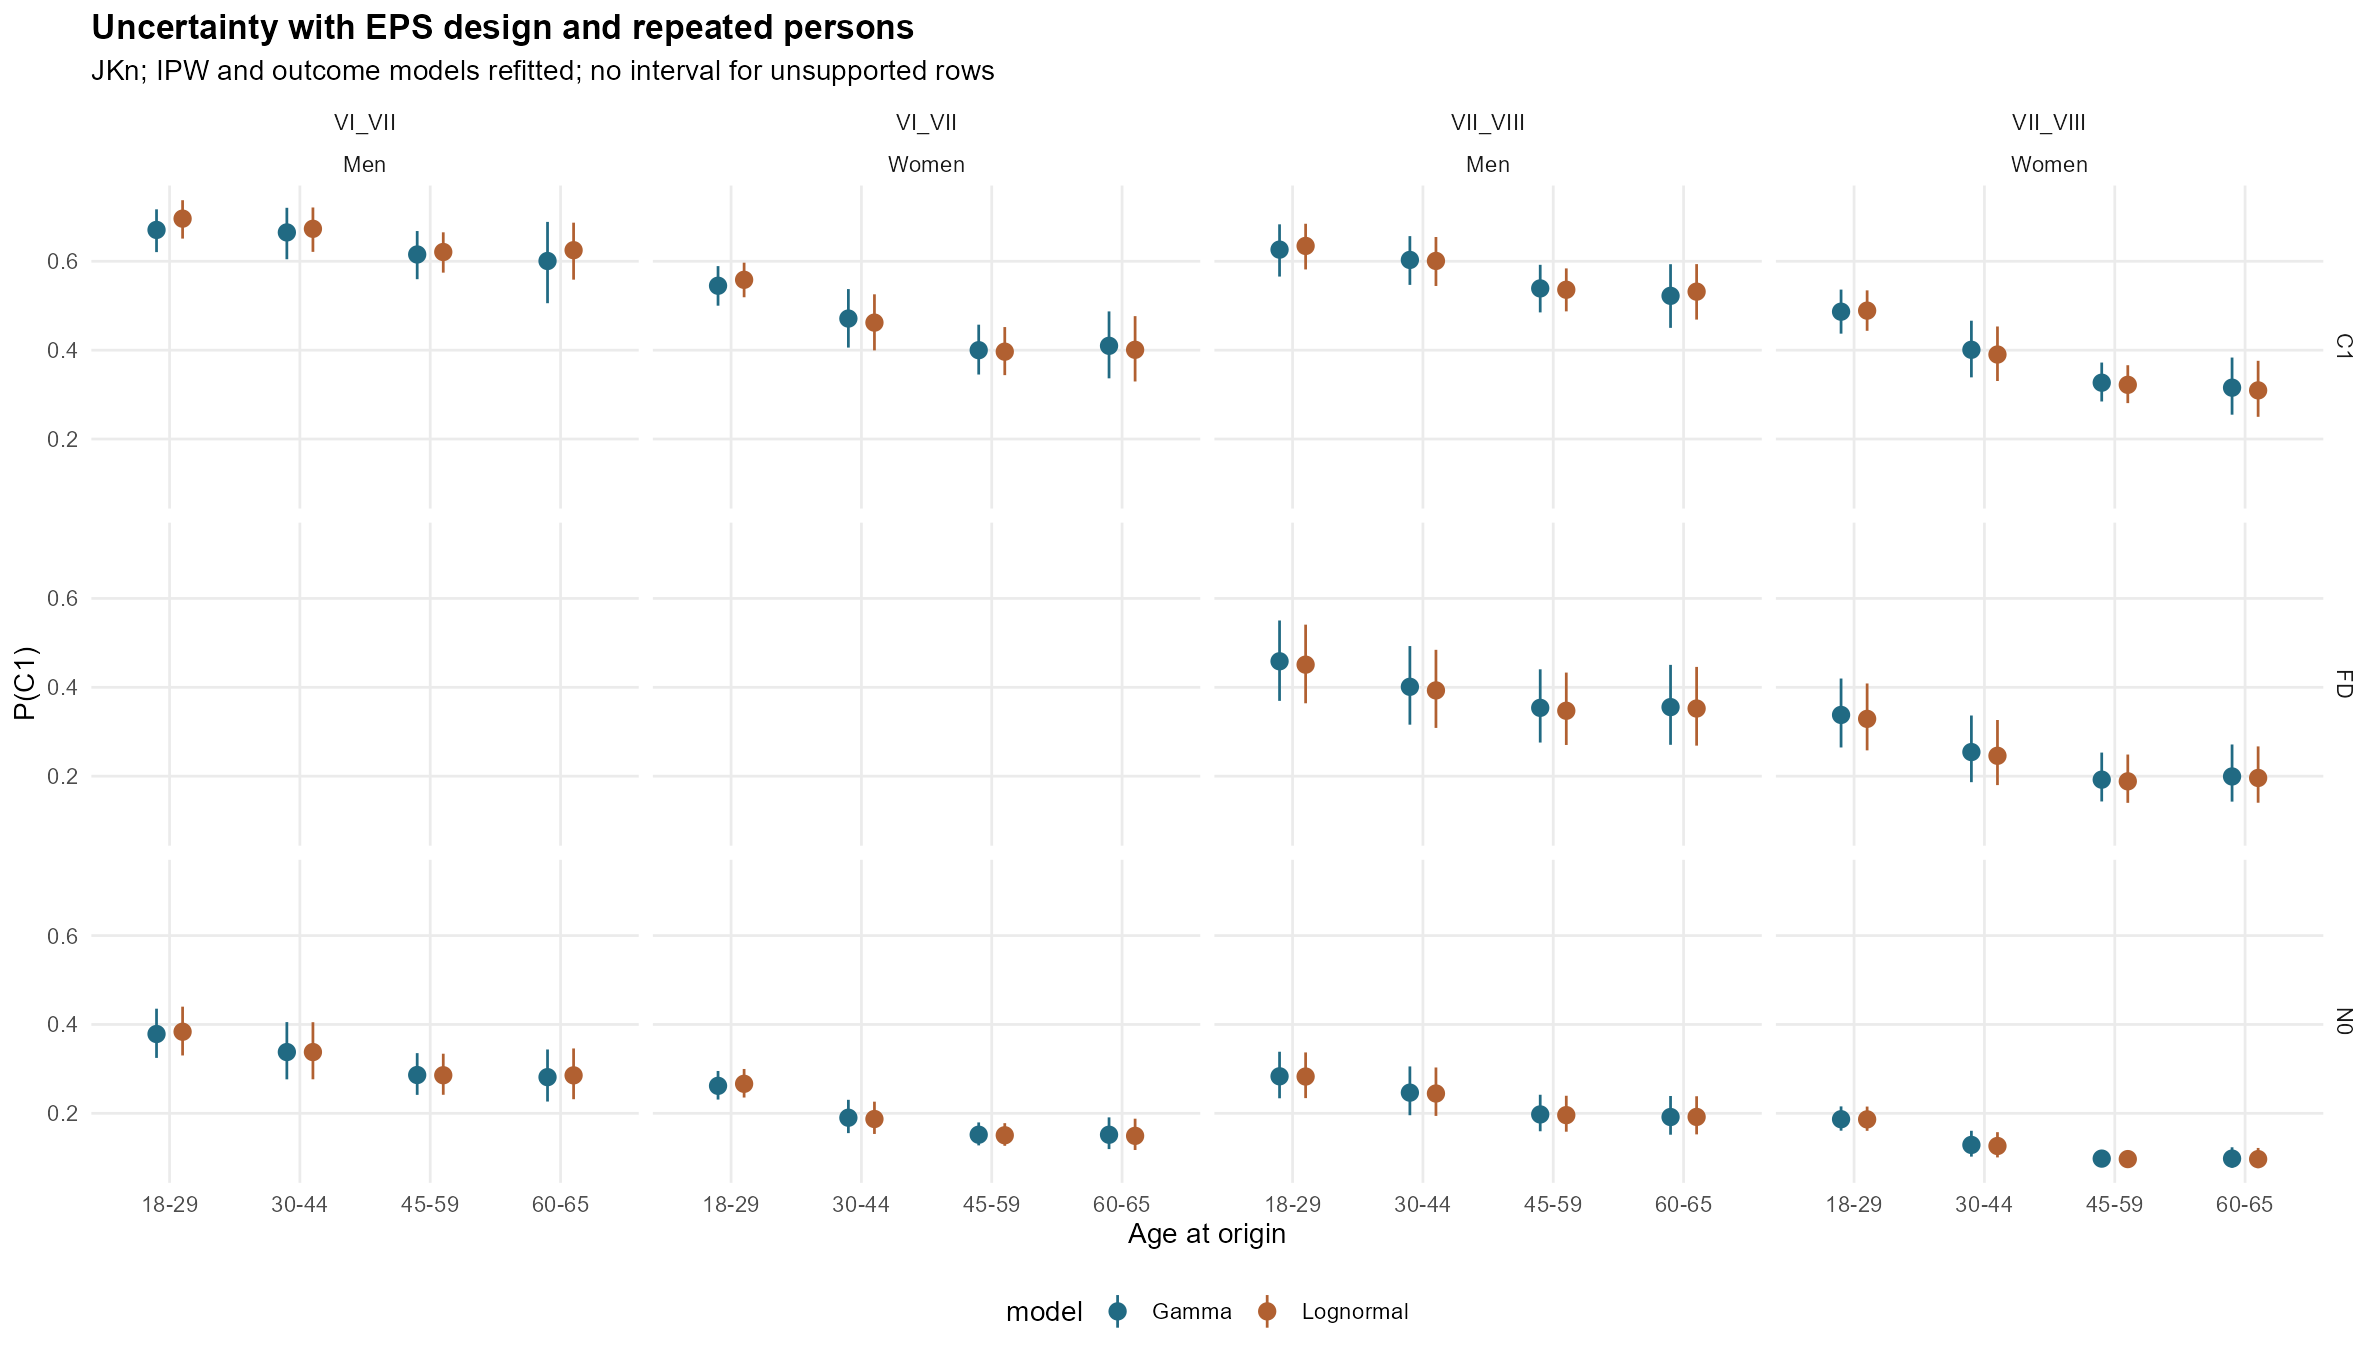

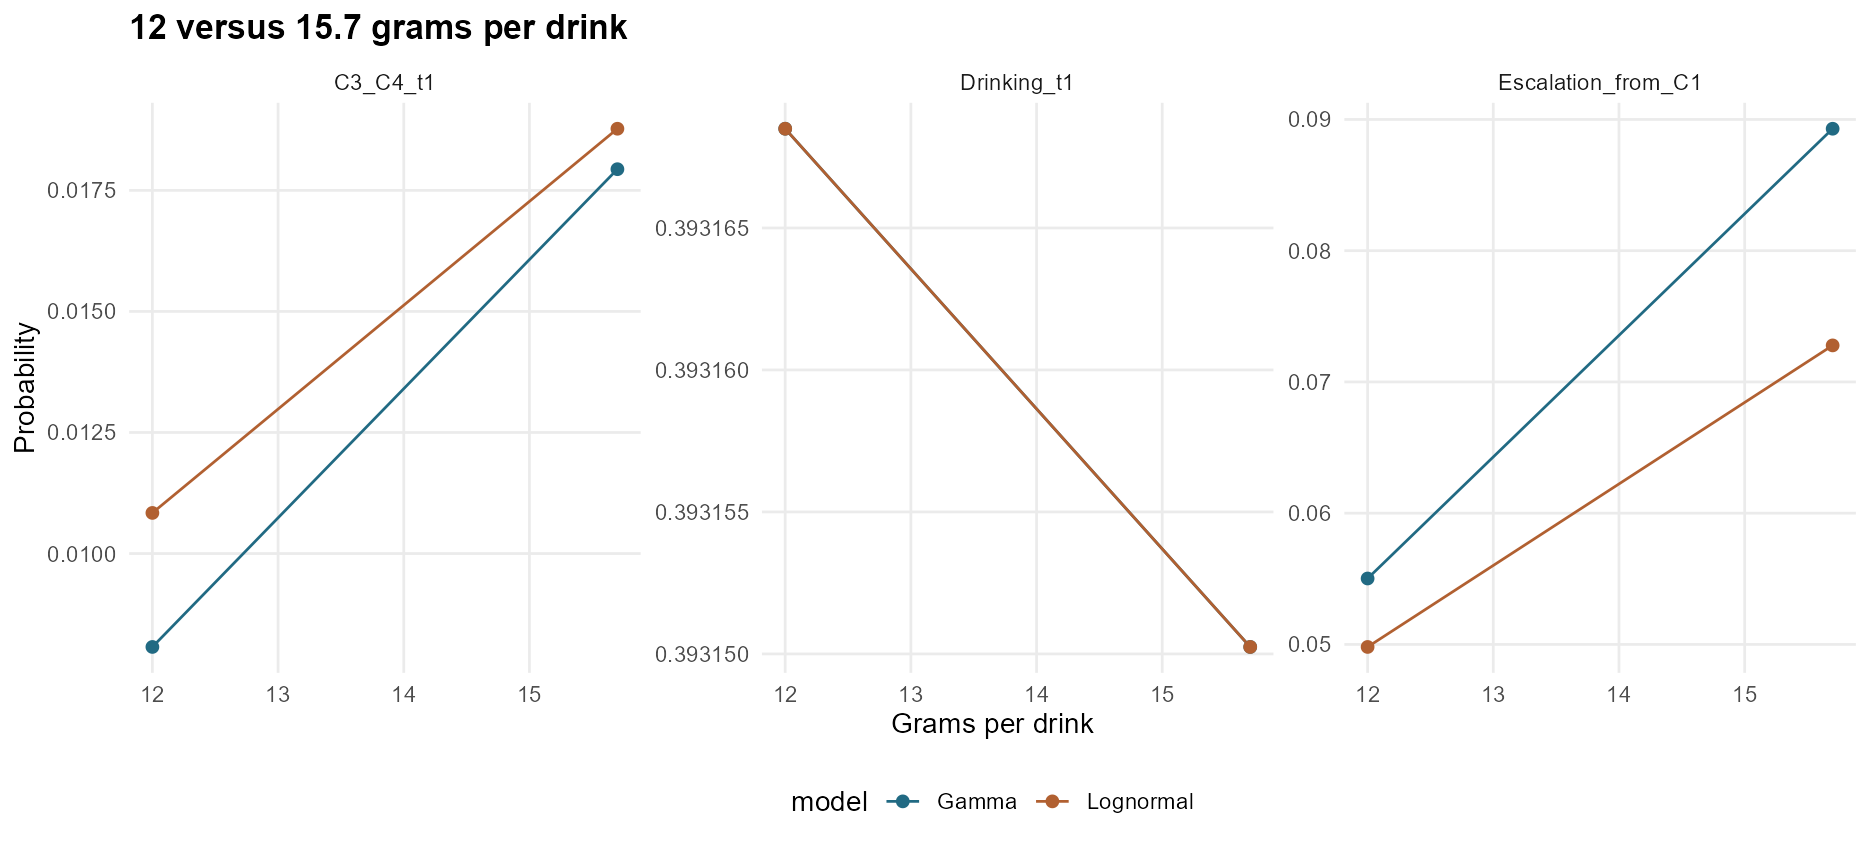

Elapsed: 0.10 minutes


In [10]:
#| label: eps-sensitivities
.t0 <- Sys.time()
ep_sensitivity <- do.call(rbind,lapply(c(12,15.7),function(g) {
 r<-ep_make_risk(ep_waves(g)); d<-ep_ipw_apply(r,ep_ipw_fit(r))
 do.call(rbind,lapply(c("Gamma","Lognormal"),function(nm) {
  pr<-ep_prob(ep_fit(d,nm),d)
  data.frame(grams_per_drink=g,model=nm,quantity=c("Drinking_t1","Escalation_from_C1","C3_C4_t1"),
   probability=c(stats::weighted.mean(1-pr[,1],d$wn),
    stats::weighted.mean(rowSums(pr[d$state0=="C1",3:5,drop=FALSE]),d$wn[d$state0=="C1"]),
    stats::weighted.mean(rowSums(pr[,4:5,drop=FALSE]),d$wn)))
 }))
}))
ep_save(ep_sensitivity,"conversion_sensitivity")
ep_weight_sens <- do.call(rbind,lapply(c("base_only","base_plus_IPW"),function(s) {
 d<-ep_d
 if(s=="base_only") for(p in ep_periods) {ii<-d$period==p;d$wn[ii]<-d$wbase[ii]/sum(d$wbase[ii])*ep_period_mass[[p]]}
 pr<-ep_prob(ep_fit(d,"Gamma"),d)
 data.frame(scenario=s,current_t1=stats::weighted.mean(1-pr[,1],d$wn),
  C3_C4_t1=stats::weighted.mean(rowSums(pr[,4:5]),d$wn))
}))
ep_save(ep_weight_sens,"weight_refit_sensitivity")
ep_hed_result<-ep_hed();ep_save(ep_hed_result$coef,"typical_quantity_signal_design_coefficients")
ep_save(ep_hed_result$proportions,"typical_quantity_signal_by_category")
ep_show(ep_sensitivity,"Conversion sensitivity, refitted models","Sensibilidad a la conversión, modelos reajustados",4)
ep_show(ep_weight_sens,"Refitted weight sensitivity","Sensibilidad de pesos con reajuste",4)
ep_plots()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Review and reproducibility

`eps_markov_review.md` documents findings, fixes and remaining limitations. Checks include absent classes, FD/N0 labels, weight-scale-invariant dispersion, disjoint person folds, origin support, rank-matching margins and generator properties.

ES/EN versions are built from the same computation and executed in fresh sessions with identical seeds. An external check compares exported numerical tables; its result is attached after both executions. Reproducing results does not prove the statistical assumptions true.

**For microsimulation:** retain Gamma and lognormal as candidates, A as reference, and unchanged C1–C4 definitions. ENPG calibration and independent validation remain pending. Sparse tails, incomplete history and unidentified singleton-stratum variance constrain interpretation.


In [11]:
#| label: eps-reproducibility
.t0 <- Sys.time()
ep_checks_table<-data.frame(check=names(ep_checks),passed=unlist(ep_checks),row.names=NULL)
ep_save(ep_checks_table,"analysis_checks")
ep_save(data.frame(seed=ep_seed,person_bootstrap_replicates=ep_B,CV_repetitions=ep_repeats,
 JKn_replicates=ncol(ep_des$multipliers),same_ID_same_multiplier=TRUE),"analysis_configuration")
ww<-as.data.frame(table(ep_warnings),stringsAsFactors=FALSE); names(ww)<-c("warning","n")
ep_save(ww,"fit_warnings")
ep_check(all(ep_checks_table$passed),"All recorded checks passed")
ep_show(ep_checks_table,"Executed checks on real EPS data","Comprobaciones ejecutadas con datos EPS reales")
si<-utils::capture.output(utils::sessionInfo())
writeLines(si[!grepl("[A-Za-z]:[/\\\\]",si)],file.path(ep_out,"session_info.txt"))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


check,passed
Published design codes agree across files,TRUE
VI-VII longitudinal weight and design are available,TRUE
Every risk-set ID has one published PSU and stratum,TRUE
Risk-set persons belong to the full VII design frame,TRUE
One row per person and interval,TRUE
Positive finite main weights,TRUE
No fabricated strict long-term origin states,TRUE
Observed pairs respect the history-state transition map,TRUE
Weight-scale invariance Gamma,TRUE
Weight-scale invariance Lognormal,TRUE


Elapsed: 0.00 minutes


## Reproduction check: PASS

Both versions ran in **fresh R kernels**, with 11 completed code cells per version and no errors. All **42 CSV files (7,246 aggregate rows)** are byte-identical across ES/EN runs. They include 111 JKn replicates and 1,000 whole-person replicates, with refitted IPW.

The external verifier checked shared source, exported results and every recorded R check. This cell reports that subsequent verification; it does not simulate another execution. Figures were inspected separately. Model assumptions and external validity still require assessment.

[Review report](eps_markov_review.md) · [File comparison](eps_markov_outputs/reproducibility_check.csv)

## References / Referencias

- Calvo E et al. (2020). *Cross-country and historical variation in alcohol consumption among older men and women*. [Article, Table 2](https://pmc.ncbi.nlm.nih.gov/articles/PMC7585691/) and [supplement, Table S2](https://ars.els-cdn.com/content/image/1-s2.0-S0376871620303847-mmc1.docx).
- Calvo et al. (2021). [Alcohol transitions and harmonized history definitions](https://pmc.ncbi.nlm.nih.gov/articles/PMC8131222/).
- EPS official design: `_eps/notes/34_Informe Técnico EPS VIII Ronda.txt`, sections on longitudinal weights and sampling variance; `_eps/notes/16_EPS - Informe Metodologico-Muestreo, Atrición, Factores, Errores Muestrales.txt`.
- EPS V limitations: `_eps/docs/2012/Dossier_Resultados_VRondaEPS2012.pdf`, p. 23; [official documentation archive](https://www.previsionsocial.gob.cl/sps/download/estudios-previsionales/encuesta-de-proteccion-social/bases-de-datos-eps/instrucciones-bd-eps-2012.rar).
- Lumley, `survey`: [singleton strata](https://r-survey.r-forge.r-project.org/survey/exmample-lonely.html), [JKn replication](https://r-survey.r-forge.r-project.org/pkgdown/docs/reference/as.svrepdesign.html), [replicate variance](https://r-survey.r-forge.r-project.org/pkgdown/docs/reference/svrVar.html).
- JRT comparison: `jrt/simulacion/Alcohol Transitions FINAL.R`; harmonization source: `eps_alcohol_prevalencia_persistencia.ipynb`.
- Architecture for subsequent microsimulation integration: [Kilian et al. (2025), Lancet Public Health](https://pubmed.ncbi.nlm.nih.gov/40885207/), DOI 10.1016/S2468-2667(25)00165-3; [SIMAH release 0.1.1](https://doi.org/10.5281/zenodo.15641639). This notebook estimates Chilean transition components; it does not execute SIMAH or import US parameter values.
